# F1TENTH Baselines: PPO, PPO-LSTM, and Offline IQL

This notebook is a self-contained Kaggle training and evaluation workflow for three baselines: a tuned feed-forward PPO, recurrent PPO-LSTM, and offline Implicit Q-Learning (IQL). It embeds the simulator, Gymnasium environment, training loops, offline expert-data collection, checkpoints, and matched held-out evaluation. It does not call project training scripts.

Run it from the repository or in a Kaggle notebook with Internet enabled so it can fetch the F1TENTH racetracks. For Kaggle, upload this notebook and enable the Internet setting. Training data for IQL is collected in the notebook using a fixed pure-pursuit behavior policy, then held fixed during IQL optimization.


In [1]:
# Install once per environment. Restart the kernel if Jupyter requests it.
#%pip install "stable-baselines3==2.9.0" "sb3-contrib==2.9.0" "gymnasium==1.2.0" "pyglet<2" "numpy<2.3" rich pandas scipy numba pillow pyyaml


In [2]:
from pathlib import Path
import os
import sys
import json
import random
import socket
import platform
import csv
import math
import time
import yaml
import matplotlib.pyplot as plt
from PIL import Image
from numba import njit
from scipy.ndimage import distance_transform_edt as edt

import gymnasium as gym
import numpy as np
import pandas as pd
import torch
# Ensure the submodule is loaded before SB3/PyTorch optimizer setup uses torch._dynamo.
import torch._utils
from gymnasium import spaces
from stable_baselines3 import PPO
from sb3_contrib import RecurrentPPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback

# Use local project maps, or fetch them when this notebook runs in Kaggle.
ROOT = Path.cwd().resolve()
if not (ROOT / "maps").is_dir() and Path("/kaggle/working").is_dir():
    ROOT = Path("/kaggle/working")
    if not (ROOT / "maps").is_dir():
        import shutil, subprocess
        checkout = ROOT / "f1tenth_racetracks"
        if not checkout.exists():
            subprocess.run(["git", "clone", "--depth", "1",
                            "https://github.com/f1tenth/f1tenth_racetracks.git",
                            str(checkout)], check=True)
        shutil.copytree(checkout, ROOT / "maps", dirs_exist_ok=True)
while not (ROOT / "maps").is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError("Run from this project or in Kaggle with Internet enabled to download the tracks.")
    ROOT = ROOT.parent
os.chdir(ROOT)
display = os.environ.get("DISPLAY", "")
HAS_DISPLAY = bool(display)
if display.startswith(":"):
    probe = socket.socket(socket.AF_UNIX, socket.SOCK_STREAM)
    try:
        probe.connect(f"/tmp/.X11-unix/X{display[1:].split('.', 1)[0]}")
    except OSError:
        HAS_DISPLAY = False
    finally:
        probe.close()
MAPS_ROOT = ROOT / "maps"
OUTPUT_DIR = ROOT / "outputs" / "ppo_notebook"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))



TRAIN_MAPS = ["Spielberg", "Austin", "MoscowRaceway"]
TRAINING_STEPS = 5_00_000        # Increase for publication-scale training
TRAINING_SEEDS = [0]       # Independent training runs
EVAL_EPISODES_PER_MAP = 5
EVAL_BASE_SEED = 10_000
MAX_EPISODE_SECONDS = 120.0

CONTROL_HZ = 20
SIM_TIMESTEP = 0.01
LIDAR_DIM = 128
LIDAR_MAX_RANGE_M = 10.0
MAX_STEER_RAD = 0.4
MAX_SPEED_MPS = 8.0

# Reward parameters. The per-second time cost makes standing still costly.
PROGRESS_WEIGHT = 1.0
CROSS_TRACK_WEIGHT = 0.15
SPEED_WEIGHT = 0.02
TIME_PENALTY_PER_SEC = 0.2
LAP_BONUS = 50.0
COLLISION_PENALTY = 80.0

def map_files(map_name):
    folder = MAPS_ROOT / map_name
    yaml_path = folder / f"{map_name}_map.yaml"
    centerline_path = folder / f"{map_name}_centerline.csv"
    image_path = next((folder / f"{map_name}_map{ext}" for ext in (".png", ".pgm")
                       if (folder / f"{map_name}_map{ext}").is_file()), None)
    if not yaml_path.is_file() or not centerline_path.is_file() or image_path is None:
        raise FileNotFoundError(f"Map {map_name!r} is incomplete under {MAPS_ROOT}")
    return yaml_path, image_path.suffix, centerline_path

def load_centerline(path):
    frame = pd.read_csv(path)
    frame.columns = [str(column).lstrip("#").strip() for column in frame.columns]
    if not {"x_m", "y_m"}.issubset(frame.columns):
        raise ValueError(f"Expected x_m,y_m columns in {path}; got {list(frame.columns)}")
    return frame[["x_m", "y_m"]].to_numpy(dtype=np.float32)

for name in TRAIN_MAPS:
    map_files(name)
print("Repository:", ROOT)
print("Train maps:", TRAIN_MAPS)
assert hasattr(torch, "_utils"), f"PyTorch install is incomplete: {torch.__file__}"
print("Torch:", torch.__version__, "SB3:", __import__("stable_baselines3").__version__)


Repository: /kaggle/working
Train maps: ['Spielberg', 'Austin', 'MoscowRaceway']
Torch: 2.11.0+cu128 SB3: 2.9.0


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


## Environment and reward

All policies observe 128 normalized LiDAR beams, normalized speed, and normalized steering (130 features) and output normalized steering and target speed. Rewards match the local PPO environment: centerline progress, cross-track distance, speed, time cost, and lap/collision outcomes. Every learned policy is evaluated on the same seeded held-out starts.

The PPO baseline uses a larger MLP, longer rollout batches, a small entropy bonus, and a KL guard. PPO-LSTM uses SB3-Contrib's RecurrentPPO with a 128-unit LSTM. IQL follows the method in Kostrikov et al. (2021), learning an expectile value function and extracting a policy with advantage-weighted regression from fixed transitions.


In [3]:
@njit(cache=True)
def perpendicular(pt):
    """
    Return a 2-vector's perpendicular vector

    Args:
        pt (np.ndarray, (2,)): input vector

    Returns:
        pt (np.ndarray, (2,)): perpendicular vector
    """
    temp = pt[0]
    pt[0] = pt[1]
    pt[1] = -1*temp
    return pt


@njit(cache=True)
def tripleProduct(a, b, c):
    """
    Return triple product of three vectors

    Args:
        a, b, c (np.ndarray, (2,)): input vectors

    Returns:
        (np.ndarray, (2,)): triple product
    """
    ac = a.dot(c)
    bc = b.dot(c)
    return b*ac - a*bc


@njit(cache=True)
def avgPoint(vertices):
    """
    Return the average point of multiple vertices

    Args:
        vertices (np.ndarray, (n, 2)): the vertices we want to find avg on

    Returns:
        avg (np.ndarray, (2,)): average point of the vertices
    """
    return np.sum(vertices, axis=0)/vertices.shape[0]


@njit(cache=True)
def indexOfFurthestPoint(vertices, d):
    """
    Return the index of the vertex furthest away along a direction in the list of vertices

    Args:
        vertices (np.ndarray, (n, 2)): the vertices we want to find avg on

    Returns:
        idx (int): index of the furthest point
    """
    return np.argmax(vertices.dot(d))


@njit(cache=True)
def support(vertices1, vertices2, d):
    """
    Minkowski sum support function for GJK

    Args:
        vertices1 (np.ndarray, (n, 2)): vertices of the first body
        vertices2 (np.ndarray, (n, 2)): vertices of the second body
        d (np.ndarray, (2, )): direction to find the support along

    Returns:
        support (np.ndarray, (n, 2)): Minkowski sum
    """
    i = indexOfFurthestPoint(vertices1, d)
    j = indexOfFurthestPoint(vertices2, -d)
    return vertices1[i] - vertices2[j]


@njit(cache=True)
def collision(vertices1, vertices2):
    """
    GJK test to see whether two bodies overlap

    Args:
        vertices1 (np.ndarray, (n, 2)): vertices of the first body
        vertices2 (np.ndarray, (n, 2)): vertices of the second body

    Returns:
        overlap (boolean): True if two bodies collide
    """
    index = 0
    simplex = np.empty((3, 2))

    position1 = avgPoint(vertices1)
    position2 = avgPoint(vertices2)

    d = position1 - position2

    if d[0] == 0 and d[1] == 0:
        d[0] = 1.0

    a = support(vertices1, vertices2, d)
    simplex[index, :] = a

    if d.dot(a) <= 0:
        return False

    d = -a

    iter_count = 0
    while iter_count < 1e3:
        a = support(vertices1, vertices2, d)
        index += 1
        simplex[index, :] = a
        if d.dot(a) <= 0:
            return False

        ao = -a

        if index < 2:
            b = simplex[0, :]
            ab = b-a
            d = tripleProduct(ab, ao, ab)
            if np.linalg.norm(d) < 1e-10:
                d = perpendicular(ab)
            continue

        b = simplex[1, :]
        c = simplex[0, :]
        ab = b-a
        ac = c-a

        acperp = tripleProduct(ab, ac, ac)

        if acperp.dot(ao) >= 0:
            d = acperp
        else:
            abperp = tripleProduct(ac, ab, ab)
            if abperp.dot(ao) < 0:
                return True
            simplex[0, :] = simplex[1, :]
            d = abperp

        simplex[1, :] = simplex[2, :]
        index -= 1

        iter_count += 1
    return False

@njit(cache=True)
def collision_multiple(vertices):
    """
    Check pair-wise collisions for all provided vertices

    Args:
        vertices (np.ndarray (num_bodies, 4, 2)): all vertices for checking pair-wise collision

    Returns:
        collisions (np.ndarray (num_vertices, )): whether each body is in collision
        collision_idx (np.ndarray (num_vertices, )): which index of other body is each index's body is in collision, -1 if not in collision
    """
    collisions = np.zeros((vertices.shape[0], ))
    collision_idx = -1 * np.ones((vertices.shape[0], ))
    # looping over all pairs
    for i in range(vertices.shape[0]-1):
        for j in range(i+1, vertices.shape[0]):
            # check collision
            vi = np.ascontiguousarray(vertices[i, :, :])
            vj = np.ascontiguousarray(vertices[j, :, :])
            ij_collision = collision(vi, vj)
            # fill in results
            if ij_collision:
                collisions[i] = 1.
                collisions[j] = 1.
                collision_idx[i] = j
                collision_idx[j] = i

    return collisions, collision_idx

"""
Utility functions for getting vertices by pose and shape
"""

@njit(cache=True)
def get_trmtx(pose):
    """
    Get transformation matrix of vehicle frame -> global frame

    Args:
        pose (np.ndarray (3, )): current pose of the vehicle

    return:
        H (np.ndarray (4, 4)): transformation matrix
    """
    x = pose[0]
    y = pose[1]
    th = pose[2]
    cos = np.cos(th)
    sin = np.sin(th)
    H = np.array([[cos, -sin, 0., x], [sin, cos, 0., y], [0., 0., 1., 0.], [0., 0., 0., 1.]])
    return H

@njit(cache=True)
def get_vertices(pose, length, width):
    """
    Utility function to return vertices of the car body given pose and size

    Args:
        pose (np.ndarray, (3, )): current world coordinate pose of the vehicle
        length (float): car length
        width (float): car width

    Returns:
        vertices (np.ndarray, (4, 2)): corner vertices of the vehicle body
    """
    H = get_trmtx(pose)
    rl = H.dot(np.asarray([[-length/2],[width/2],[0.], [1.]])).flatten()
    rr = H.dot(np.asarray([[-length/2],[-width/2],[0.], [1.]])).flatten()
    fl = H.dot(np.asarray([[length/2],[width/2],[0.], [1.]])).flatten()
    fr = H.dot(np.asarray([[length/2],[-width/2],[0.], [1.]])).flatten()
    rl = rl/rl[3]
    rr = rr/rr[3]
    fl = fl/fl[3]
    fr = fr/fr[3]
    vertices = np.asarray([[rl[0], rl[1]], [rr[0], rr[1]], [fr[0], fr[1]], [fl[0], fl[1]]])
    return vertices

In [4]:
@njit(cache=True)
def accl_constraints(vel, accl, v_switch, a_max, v_min, v_max):
    """
    Acceleration constraints, adjusts the acceleration based on constraints

        Args:
            vel (float): current velocity of the vehicle
            accl (float): unconstraint desired acceleration
            v_switch (float): switching velocity (velocity at which the acceleration is no longer able to create wheel spin)
            a_max (float): maximum allowed acceleration
            v_min (float): minimum allowed velocity
            v_max (float): maximum allowed velocity

        Returns:
            accl (float): adjusted acceleration
    """

    # positive accl limit
    if vel > v_switch:
        pos_limit = a_max*v_switch/vel
    else:
        pos_limit = a_max

    # accl limit reached?
    if (vel <= v_min and accl <= 0) or (vel >= v_max and accl >= 0):
        accl = 0.
    elif accl <= -a_max:
        accl = -a_max
    elif accl >= pos_limit:
        accl = pos_limit

    return accl

@njit(cache=True)
def steering_constraint(steering_angle, steering_velocity, s_min, s_max, sv_min, sv_max):
    """
    Steering constraints, adjusts the steering velocity based on constraints

        Args:
            steering_angle (float): current steering_angle of the vehicle
            steering_velocity (float): unconstraint desired steering_velocity
            s_min (float): minimum steering angle
            s_max (float): maximum steering angle
            sv_min (float): minimum steering velocity
            sv_max (float): maximum steering velocity

        Returns:
            steering_velocity (float): adjusted steering velocity
    """

    # constraint steering velocity
    if (steering_angle <= s_min and steering_velocity <= 0) or (steering_angle >= s_max and steering_velocity >= 0):
        steering_velocity = 0.
    elif steering_velocity <= sv_min:
        steering_velocity = sv_min
    elif steering_velocity >= sv_max:
        steering_velocity = sv_max

    return steering_velocity


@njit(cache=True)
def vehicle_dynamics_ks(x, u_init, mu, C_Sf, C_Sr, lf, lr, h, m, I, s_min, s_max, sv_min, sv_max, v_switch, a_max, v_min, v_max):
    """
    Single Track Kinematic Vehicle Dynamics.

        Args:
            x (numpy.ndarray (3, )): vehicle state vector (x1, x2, x3, x4, x5)
                x1: x position in global coordinates
                x2: y position in global coordinates
                x3: steering angle of front wheels
                x4: velocity in x direction
                x5: yaw angle
            u (numpy.ndarray (2, )): control input vector (u1, u2)
                u1: steering angle velocity of front wheels
                u2: longitudinal acceleration

        Returns:
            f (numpy.ndarray): right hand side of differential equations
    """
    # wheelbase
    lwb = lf + lr

    # constraints
    u = np.array([steering_constraint(x[2], u_init[0], s_min, s_max, sv_min, sv_max), accl_constraints(x[3], u_init[1], v_switch, a_max, v_min, v_max)])

    # system dynamics
    f = np.array([x[3]*np.cos(x[4]),
         x[3]*np.sin(x[4]),
         u[0],
         u[1],
         x[3]/lwb*np.tan(x[2])])
    return f

@njit(cache=True)
def vehicle_dynamics_st(x, u_init, mu, C_Sf, C_Sr, lf, lr, h, m, I, s_min, s_max, sv_min, sv_max, v_switch, a_max, v_min, v_max):
    """
    Single Track Dynamic Vehicle Dynamics.

        Args:
            x (numpy.ndarray (3, )): vehicle state vector (x1, x2, x3, x4, x5, x6, x7)
                x1: x position in global coordinates
                x2: y position in global coordinates
                x3: steering angle of front wheels
                x4: velocity in x direction
                x5: yaw angle
                x6: yaw rate
                x7: slip angle at vehicle center
            u (numpy.ndarray (2, )): control input vector (u1, u2)
                u1: steering angle velocity of front wheels
                u2: longitudinal acceleration

        Returns:
            f (numpy.ndarray): right hand side of differential equations
    """

    # gravity constant m/s^2
    g = 9.81

    # constraints
    u = np.array([steering_constraint(x[2], u_init[0], s_min, s_max, sv_min, sv_max), accl_constraints(x[3], u_init[1], v_switch, a_max, v_min, v_max)])

    # switch to kinematic model for small velocities
    if abs(x[3]) < 0.5:
        # wheelbase
        lwb = lf + lr

        # system dynamics
        x_ks = x[0:5]
        f_ks = vehicle_dynamics_ks(x_ks, u, mu, C_Sf, C_Sr, lf, lr, h, m, I, s_min, s_max, sv_min, sv_max, v_switch, a_max, v_min, v_max)
        f = np.hstack((f_ks, np.array([u[1]/lwb*np.tan(x[2])+x[3]/(lwb*np.cos(x[2])**2)*u[0],
        0])))

    else:
        # system dynamics
        f = np.array([x[3]*np.cos(x[6] + x[4]),
            x[3]*np.sin(x[6] + x[4]),
            u[0],
            u[1],
            x[5],
            -mu*m/(x[3]*I*(lr+lf))*(lf**2*C_Sf*(g*lr-u[1]*h) + lr**2*C_Sr*(g*lf + u[1]*h))*x[5] \
                +mu*m/(I*(lr+lf))*(lr*C_Sr*(g*lf + u[1]*h) - lf*C_Sf*(g*lr - u[1]*h))*x[6] \
                +mu*m/(I*(lr+lf))*lf*C_Sf*(g*lr - u[1]*h)*x[2],
            (mu/(x[3]**2*(lr+lf))*(C_Sr*(g*lf + u[1]*h)*lr - C_Sf*(g*lr - u[1]*h)*lf)-1)*x[5] \
                -mu/(x[3]*(lr+lf))*(C_Sr*(g*lf + u[1]*h) + C_Sf*(g*lr-u[1]*h))*x[6] \
                +mu/(x[3]*(lr+lf))*(C_Sf*(g*lr-u[1]*h))*x[2]])

    return f

@njit(cache=True)
def pid(speed, steer, current_speed, current_steer, max_sv, max_a, max_v, min_v):
    """
    Basic controller for speed/steer -> accl./steer vel.

        Args:
            speed (float): desired input speed
            steer (float): desired input steering angle

        Returns:
            accl (float): desired input acceleration
            sv (float): desired input steering velocity
    """
    # steering
    steer_diff = steer - current_steer
    if np.fabs(steer_diff) > 1e-4:
        sv = (steer_diff / np.fabs(steer_diff)) * max_sv
    else:
        sv = 0.0

    # accl
    vel_diff = speed - current_speed
    # currently forward
    if current_speed > 0.:
        if (vel_diff > 0):
            # accelerate
            kp = 10.0 * max_a / max_v
            accl = kp * vel_diff
        else:
            # braking
            kp = 10.0 * max_a / (-min_v)
            accl = kp * vel_diff
    # currently backwards
    else:
        if (vel_diff > 0):
            # braking
            kp = 2.0 * max_a / max_v
            accl = kp * vel_diff
        else:
            # accelerating
            kp = 2.0 * max_a / (-min_v)
            accl = kp * vel_diff

    return accl, sv

def func_KS(x, t, u, mu, C_Sf, C_Sr, lf, lr, h, m, I, s_min, s_max, sv_min, sv_max, v_switch, a_max, v_min, v_max):
    f = vehicle_dynamics_ks(x, u, mu, C_Sf, C_Sr, lf, lr, h, m, I, s_min, s_max, sv_min, sv_max, v_switch, a_max, v_min, v_max)
    return f

def func_ST(x, t, u, mu, C_Sf, C_Sr, lf, lr, h, m, I, s_min, s_max, sv_min, sv_max, v_switch, a_max, v_min, v_max):
    f = vehicle_dynamics_st(x, u, mu, C_Sf, C_Sr, lf, lr, h, m, I, s_min, s_max, sv_min, sv_max, v_switch, a_max, v_min, v_max)
    return f

In [5]:
def get_dt(bitmap, resolution):
    """
    Distance transformation, returns the distance matrix from the input bitmap.
    Uses scipy.ndimage, cannot be JITted.

        Args:
            bitmap (numpy.ndarray, (n, m)): input binary bitmap of the environment, where 0 is obstacles, and 255 (or anything > 0) is freespace
            resolution (float): resolution of the input bitmap (m/cell)

        Returns:
            dt (numpy.ndarray, (n, m)): output distance matrix, where each cell has the corresponding distance (in meters) to the closest obstacle
    """
    dt = resolution * edt(bitmap)
    return dt

@njit(cache=True)
def xy_2_rc(x, y, orig_x, orig_y, orig_c, orig_s, height, width, resolution):
    """
    Translate (x, y) coordinate into (r, c) in the matrix

        Args:
            x (float): coordinate in x (m)
            y (float): coordinate in y (m)
            orig_x (float): x coordinate of the map origin (m)
            orig_y (float): y coordinate of the map origin (m)
        
        Returns:
            r (int): row number in the transform matrix of the given point
            c (int): column number in the transform matrix of the given point
    """
    # translation
    x_trans = x - orig_x
    y_trans = y - orig_y

    # rotation
    x_rot = x_trans * orig_c + y_trans * orig_s
    y_rot = -x_trans * orig_s + y_trans * orig_c

    # clip the state to be a cell
    if x_rot < 0 or x_rot >= width * resolution or y_rot < 0 or y_rot >= height * resolution:
        c = -1
        r = -1
    else:
        c = int(x_rot/resolution)
        r = int(y_rot/resolution)

    return r, c

@njit(cache=True)
def distance_transform(x, y, orig_x, orig_y, orig_c, orig_s, height, width, resolution, dt):
    """
    Look up corresponding distance in the distance matrix

        Args:
            x (float): x coordinate of the lookup point
            y (float): y coordinate of the lookup point
            orig_x (float): x coordinate of the map origin (m)
            orig_y (float): y coordinate of the map origin (m)

        Returns:
            distance (float): corresponding shortest distance to obstacle in meters
    """
    r, c = xy_2_rc(x, y, orig_x, orig_y, orig_c, orig_s, height, width, resolution)
    distance = dt[r, c]
    return distance

@njit(cache=True)
def trace_ray(x, y, theta_index, sines, cosines, eps, orig_x, orig_y, orig_c, orig_s, height, width, resolution, dt, max_range):
    """
    Find the length of a specific ray at a specific scan angle theta
    Purely math calculation and loops, should be JITted.

        Args:
            x (float): current x coordinate of the ego (scan) frame
            y (float): current y coordinate of the ego (scan) frame
            theta_index(int): current index of the scan beam in the scan range
            sines (numpy.ndarray (n, )): pre-calculated sines of the angle array
            cosines (numpy.ndarray (n, )): pre-calculated cosines ...

        Returns:
            total_distance (float): the distance to first obstacle on the current scan beam
    """
    
    # int casting, and index precal trigs
    theta_index_ = int(theta_index)
    s = sines[theta_index_]
    c = cosines[theta_index_]

    # distance to nearest initialization
    dist_to_nearest = distance_transform(x, y, orig_x, orig_y, orig_c, orig_s, height, width, resolution, dt)
    total_dist = dist_to_nearest

    # ray tracing iterations
    while dist_to_nearest > eps and total_dist <= max_range:
        # move in the direction of the ray by dist_to_nearest
        x += dist_to_nearest * c
        y += dist_to_nearest * s

        # update dist_to_nearest for current point on ray
        # also keeps track of total ray length
        dist_to_nearest = distance_transform(x, y, orig_x, orig_y, orig_c, orig_s, height, width, resolution, dt)
        total_dist += dist_to_nearest

    if total_dist > max_range:
        total_dist = max_range
    
    return total_dist

@njit(cache=True)
def get_scan(pose, theta_dis, fov, num_beams, theta_index_increment, sines, cosines, eps, orig_x, orig_y, orig_c, orig_s, height, width, resolution, dt, max_range):
    """
    Perform the scan for each discretized angle of each beam of the laser, loop heavy, should be JITted

        Args:
            pose (numpy.ndarray(3, )): current pose of the scan frame in the map
            theta_dis (int): number of steps to discretize the angles between 0 and 2pi for look up
            fov (float): field of view of the laser scan
            num_beams (int): number of beams in the scan
            theta_index_increment (float): increment between angle indices after discretization

        Returns:
            scan (numpy.ndarray(n, )): resulting laser scan at the pose, n=num_beams
    """
    # empty scan array init
    scan = np.empty((num_beams,))

    # make theta discrete by mapping the range [-pi, pi] onto [0, theta_dis]
    theta_index = theta_dis * (pose[2] - fov/2.)/(2. * np.pi)

    # make sure it's wrapped properly
    theta_index = np.fmod(theta_index, theta_dis)
    while (theta_index < 0):
        theta_index += theta_dis

    # sweep through each beam
    for i in range(0, num_beams):
        # trace the current beam
        scan[i] = trace_ray(pose[0], pose[1], theta_index, sines, cosines, eps, orig_x, orig_y, orig_c, orig_s, height, width, resolution, dt, max_range)

        # increment the beam index
        theta_index += theta_index_increment

        # make sure it stays in the range [0, theta_dis)
        while theta_index >= theta_dis:
            theta_index -= theta_dis

    return scan

@njit(cache=True)
def check_ttc_jit(scan, vel, scan_angles, cosines, side_distances, ttc_thresh):
    """
    Checks the iTTC of each beam in a scan for collision with environment

    Args:
        scan (np.ndarray(num_beams, )): current scan to check
        vel (float): current velocity
        scan_angles (np.ndarray(num_beams, )): precomped angles of each beam
        cosines (np.ndarray(num_beams, )): precomped cosines of the scan angles
        side_distances (np.ndarray(num_beams, )): precomped distances at each beam from the laser to the sides of the car
        ttc_thresh (float): threshold for iTTC for collision

    Returns:
        in_collision (bool): whether vehicle is in collision with environment
        collision_angle (float): at which angle the collision happened
    """
    if vel != 0.0:
        num_beams = scan.shape[0]
        for i in range(num_beams):
            proj_vel = vel*cosines[i]
            ttc = (scan[i] - side_distances[i])/proj_vel
            if (ttc < ttc_thresh) and (ttc >= 0.0):
                in_collision = True
                break
    else:
        in_collision = False

    return in_collision

@njit(cache=True)
def cross(v1, v2):
    """
    Cross product of two 2-vectors

    Args:
        v1, v2 (np.ndarray(2, )): input vectors

    Returns:
        crossproduct (float): cross product
    """
    return v1[0]*v2[1]-v1[1]*v2[0]

@njit(cache=True)
def are_collinear(pt_a, pt_b, pt_c):
    """
    Checks if three points are collinear in 2D

    Args:
        pt_a, pt_b, pt_c (np.ndarray(2, )): points to check in 2D

    Returns:
        col (bool): whether three points are collinear
    """
    tol = 1e-8
    ba = pt_b - pt_a
    ca = pt_a - pt_c
    col = np.fabs(cross(ba, ca)) < tol
    return col

@njit(cache=True)
def get_range(pose, beam_theta, va, vb):
    """
    Get the distance at a beam angle to the vector formed by two of the four vertices of a vehicle

    Args:
        pose (np.ndarray(3, )): pose of the scanning vehicle
        beam_theta (float): angle of the current beam (world frame)
        va, vb (np.ndarray(2, )): the two vertices forming an edge

    Returns:
        distance (float): smallest distance at beam theta from scanning pose to edge
    """
    o = pose[0:2]
    v1 = o - va
    v2 = vb - va
    v3 = np.array([np.cos(beam_theta + np.pi/2.), np.sin(beam_theta + np.pi/2.)])

    denom = v2.dot(v3)
    distance = np.inf

    if np.fabs(denom) > 0.0:
        d1 = cross(v2, v1) / denom
        d2 = v1.dot(v3) / denom
        if d1 >= 0.0 and d2 >= 0.0 and d2 <= 1.0:
            distance = d1
    elif are_collinear(o, va, vb):
        da = np.linalg.norm(va - o)
        db = np.linalg.norm(vb - o)
        distance = min(da, db)

    return distance

@njit(cache=True)
def ray_cast(pose, scan, scan_angles, vertices):
    """
    Modify a scan by ray casting onto another agent's four vertices

    Args:
        pose (np.ndarray(3, )): pose of the vehicle performing scan
        scan (np.ndarray(num_beams, )): original scan to modify
        scan_angles (np.ndarray(num_beams, )): corresponding beam angles
        vertices (np.ndarray(4, 2)): four vertices of a vehicle pose
    
    Returns:
        new_scan (np.ndarray(num_beams, )): modified scan
    """
    num_beams = scan.shape[0]

    # pad vertices so loops around
    looped_vertices = np.empty((5, 2))
    looped_vertices[0:4, :] = vertices
    looped_vertices[4, :] = vertices[0, :]

    # looping over beams
    for i in range(num_beams):
        # looping over vertices
        for j in range(4):
            # check if original scan is longer than ray casted distance
            scan_range = get_range(pose, pose[2]+scan_angles[i], looped_vertices[j,:], looped_vertices[j+1,:])
            if scan_range < scan[i]:
                scan[i] = scan_range

    return scan

class ScanSimulator2D(object):
    """
    2D LIDAR scan simulator class

    Init params:
        num_beams (int): number of beams in the scan
        fov (float): field of view of the laser scan
        eps (float, default=0.0001): ray tracing iteration termination condition
        theta_dis (int, default=2000): number of steps to discretize the angles between 0 and 2pi for look up
        max_range (float, default=30.0): maximum range of the laser
    """

    def __init__(self, num_beams, fov, eps=0.0001, theta_dis=2000, max_range=30.0):
        # initialization 
        self.num_beams = num_beams
        self.fov = fov
        self.eps = eps
        self.theta_dis = theta_dis
        self.max_range = max_range
        self.angle_increment = self.fov / (self.num_beams - 1)
        self.theta_index_increment = theta_dis * self.angle_increment / (2. * np.pi)
        self.orig_c = None
        self.orig_s = None
        self.orig_x = None
        self.orig_y = None
        self.map_height = None
        self.map_width = None
        self.map_resolution = None
        self.dt = None
        self.map_img = None
        
        # precomputing corresponding cosines and sines of the angle array
        theta_arr = np.linspace(0.0, 2*np.pi, num=theta_dis)
        self.sines = np.sin(theta_arr)
        self.cosines = np.cos(theta_arr)
    
    def set_map(self, map_path, map_ext):
        """
        Set the bitmap of the scan simulator by path

            Args:
                map_path (str): path to the map yaml file
                map_ext (str): extension (image type) of the map image

            Returns:
                flag (bool): if image reading and loading is successful
        """
        # TODO: do we open the option to flip the images, and turn rgb into grayscale? or specify the exact requirements in documentation.
        # TODO: throw error if image specification isn't met

        with open(map_path, 'r') as yaml_stream:
            try:
                map_metadata = yaml.safe_load(yaml_stream)
                self.map_resolution = map_metadata['resolution']
                self.origin = map_metadata['origin']
                map_img_name = map_metadata['image']
            except yaml.YAMLError as ex:
                print(ex)

        map_img_path = "maps/"+ map_img_name.split("_")[0]+"/" + map_img_name
        # map_img_path = os.path.splitext(map_path)[0] + map_ext
        self.map_img = np.array(Image.open(map_img_path).transpose(Image.FLIP_TOP_BOTTOM))
        self.map_img = self.map_img.astype(np.float64)

        # grayscale -> binary
        self.map_img[self.map_img <= 128.] = 0.
        self.map_img[self.map_img > 128.] = 255.

        self.map_height = self.map_img.shape[0]
        self.map_width = self.map_img.shape[1]

        # calculate map parameters
        self.orig_x = self.origin[0]
        self.orig_y = self.origin[1]
        self.orig_s = np.sin(self.origin[2])
        self.orig_c = np.cos(self.origin[2])

        # get the distance transform
        self.dt = get_dt(self.map_img, self.map_resolution)

        return True

    def scan(self, pose, rng, std_dev=0.01):
        """
        Perform simulated 2D scan by pose on the given map

            Args:
                pose (numpy.ndarray (3, )): pose of the scan frame (x, y, theta)
                rng (numpy.random.Generator): random number generator to use for whitenoise in scan, or None
                std_dev (float, default=0.01): standard deviation of the generated whitenoise in the scan

            Returns:
                scan (numpy.ndarray (n, )): data array of the laserscan, n=num_beams

            Raises:
                ValueError: when scan is called before a map is set
        """
        
        if self.map_height is None:
            raise ValueError('Map is not set for scan simulator.')
        
        scan = get_scan(pose, self.theta_dis, self.fov, self.num_beams, self.theta_index_increment, self.sines, self.cosines, self.eps, self.orig_x, self.orig_y, self.orig_c, self.orig_s, self.map_height, self.map_width, self.map_resolution, self.dt, self.max_range)

        if rng is not None:
            noise = rng.normal(0., std_dev, size=self.num_beams)
            scan += noise
            
        return scan

    def get_increment(self):
        return self.angle_increment

    def check_location(self, pose):
        if check_bounds(pose[0], pose[1], self.orig_x, self.orig_y, self.orig_c, self.orig_s, self.map_height, self.map_width, self.map_resolution):
            return True
        d = distance_transform(pose[0], pose[1], self.orig_x, self.orig_y, self.orig_c, self.orig_s, self.map_height, self.map_width, self.map_resolution, self.dt)
        if d < 0.001: #1mm
            return True
        return False


@njit(cache=True)
def check_bounds(x, y, orig_x, orig_y, orig_c, orig_s, height, width, resolution):

    # translation
    x_trans = x - orig_x
    y_trans = y - orig_y

    # rotation
    x_rot = x_trans * orig_c + y_trans * orig_s
    y_rot = -x_trans * orig_s + y_trans * orig_c

    # clip the state to be a cell
    if x_rot < 0 or x_rot >= width * resolution or y_rot < 0 or y_rot >= height * resolution:
        return True
    return False

In [6]:
if HAS_DISPLAY:
    import pyglet
    pyglet.options["debug_gl"] = False
    from pyglet.gl import *

    # opengl stuff

    # other

    # helpers

    # zooming constants
    ZOOM_IN_FACTOR = 1.2
    ZOOM_OUT_FACTOR = 1/ZOOM_IN_FACTOR

    # vehicle shape constants
    CAR_LENGTH = 0.58
    CAR_WIDTH = 0.31

    class EnvRenderer(pyglet.window.Window):
        """
        A window class inherited from pyglet.window.Window, handles the camera/projection interaction, resizing window, and rendering the environment
        """
        def __init__(self, width, height, *args, **kwargs):
            """
            Class constructor

            Args:
                width (int): width of the window
                height (int): height of the window

            Returns:
                None
            """
            conf = Config(sample_buffers=1,
                          samples=4,
                          depth_size=16,
                          double_buffer=True)
            super().__init__(width, height, config=conf, resizable=True, vsync=False, *args, **kwargs)

            # gl init
            glClearColor(9/255, 32/255, 87/255, 1.)

            # initialize camera values
            self.left = -width/2
            self.right = width/2
            self.bottom = -height/2
            self.top = height/2
            self.zoom_level = 1.2
            self.zoomed_width = width
            self.zoomed_height = height

            # current batch that keeps track of all graphics
            self.batch = pyglet.graphics.Batch()

            # current env map
            self.map_points = None
        
            # current env agent poses, (num_agents, 3), columns are (x, y, theta)
            self.poses = None

            # current env agent vertices, (num_agents, 4, 2), 2nd and 3rd dimensions are the 4 corners in 2D
            self.vertices = None

            # obstacles
            self.obstacle_poses = None
            self.obstacles = None

            # current score label
            self.score_label = pyglet.text.Label(
                    'Lap Time: {laptime:.2f}, Ego Lap Count: {count:.0f}'.format(
                        laptime=0.0, count=0.0),
                    font_size=36,
                    x=0,
                    y=-800,
                    anchor_x='center',
                    anchor_y='center',
                    # width=0.01,
                    # height=0.01,
                    color=(255, 255, 255, 255),
                    batch=self.batch)

            self.fps_display = pyglet.window.FPSDisplay(self)

        def update_map(self, map_name, map_ext):
            """
            Update the map being drawn by the renderer. Converts image to a list of 3D points representing each obstacle pixel in the map.

            Args:
                map_path (str): absolute path to the map without extensions
                map_ext (str): extension for the map image file

            Returns:
                None
            """

            # load map metadata
            map_path = "maps/" + map_name  
            with open(map_path+ '.yaml', 'r') as yaml_stream:
                try:
                    map_metadata = yaml.safe_load(yaml_stream)
                    map_resolution = map_metadata['resolution']
                    origin = map_metadata['origin']
                    origin_x = origin[0]
                    origin_y = origin[1]
                    map_img_name = map_metadata['image']
                except yaml.YAMLError as ex:
                    print(ex)

            map_img_path = "maps/" + map_img_name
            map_img = np.array(Image.open(map_img_path).transpose(Image.FLIP_TOP_BOTTOM)).astype(np.float64)
            map_height = map_img.shape[0]
            map_width = map_img.shape[1]

            # convert map pixels to coordinates
            range_x = np.arange(map_width)
            range_y = np.arange(map_height)
            map_x, map_y = np.meshgrid(range_x, range_y)
            map_x = (map_x * map_resolution + origin_x).flatten()
            map_y = (map_y * map_resolution + origin_y).flatten()
            map_z = np.zeros(map_y.shape)
            map_coords = np.vstack((map_x, map_y, map_z))

            # mask and only leave the obstacle points
            map_mask = map_img == 0.0
            map_mask_flat = map_mask.flatten()
            map_points = 50. * map_coords[:, map_mask_flat].T
            for i in range(map_points.shape[0]):
                self.batch.add(1, GL_POINTS, None, ('v3f/stream', [map_points[i, 0], map_points[i, 1], map_points[i, 2]]), ('c3B/stream', [183, 193, 222]))
            self.map_points = map_points

        def add_obstacles(self, obs_locations, obs_size):
            """
            Adds green obstacles to the map

            Args:
                obs_locations (np.ndarray(n_obstacles, 2)): coordinates of obstacles to add
                obs_size (list(2)): size of obstacles
        
            Returns:
                None
            """
            if self.obstacle_poses is None:
                self.obstacles = []
                for i in range(len(obs_locations)):
                    vertices_np = get_vertices(np.array([0., 0., 0.]), obs_size[0], obs_size[1])
                    vertices = list(vertices_np.flatten())
                    # obstacle = self.batch.add(4, GL_QUADS, None, ('v2f', vertices), ('c3B', [172, 97, 185, 172, 97, 185, 172, 97, 185, 172, 97, 185]))
                    obstacle = self.batch.add(4, GL_QUADS, None, ('v2f', vertices), ('c3B', [0, 225, 0, 0, 225, 0, 0, 225, 0, 0, 225, 0]))
                    self.obstacles.append(obstacle)

            poses_x = obs_locations[:, 0]
            poses_y = obs_locations[:, 1]
            poses_theta = np.ones_like(poses_x) * np.pi/2

            poses = np.stack((poses_x, poses_y, poses_theta)).T
            for j in range(poses.shape[0]):
                vertices_np = 50. * get_vertices(poses[j, :], obs_size[0], obs_size[1])
                vertices = list(vertices_np.flatten())
                self.obstacles[j].vertices = vertices
            self.obstacle_poses = poses

        def on_resize(self, width, height):
            """
            Callback function on window resize, overrides inherited method, and updates camera values on top of the inherited on_resize() method.

            Potential improvements on current behavior: zoom/pan resets on window resize.

            Args:
                width (int): new width of window
                height (int): new height of window

            Returns:
                None
            """

            # call overrided function
            super().on_resize(width, height)

            # update camera value
            (width, height) = self.get_size()
            self.left = -self.zoom_level * width/2
            self.right = self.zoom_level * width/2
            self.bottom = -self.zoom_level * height/2
            self.top = self.zoom_level * height/2
            self.zoomed_width = self.zoom_level * width
            self.zoomed_height = self.zoom_level * height

        def on_mouse_drag(self, x, y, dx, dy, buttons, modifiers):
            """
            Callback function on mouse drag, overrides inherited method.

            Args:
                x (int): Distance in pixels from the left edge of the window.
                y (int): Distance in pixels from the bottom edge of the window.
                dx (int): Relative X position from the previous mouse position.
                dy (int): Relative Y position from the previous mouse position.
                buttons (int): Bitwise combination of the mouse buttons currently pressed.
                modifiers (int): Bitwise combination of any keyboard modifiers currently active.

            Returns:
                None
            """

            # pan camera
            self.left -= dx * self.zoom_level
            self.right -= dx * self.zoom_level
            self.bottom -= dy * self.zoom_level
            self.top -= dy * self.zoom_level

        def on_mouse_scroll(self, x, y, dx, dy):
            """
            Callback function on mouse scroll, overrides inherited method.

            Args:
                x (int): Distance in pixels from the left edge of the window.
                y (int): Distance in pixels from the bottom edge of the window.
                scroll_x (float): Amount of movement on the horizontal axis.
                scroll_y (float): Amount of movement on the vertical axis.

            Returns:
                None
            """

            # Get scale factor
            f = ZOOM_IN_FACTOR if dy > 0 else ZOOM_OUT_FACTOR if dy < 0 else 1

            # If zoom_level is in the proper range
            if .01 < self.zoom_level * f < 10:

                self.zoom_level *= f

                (width, height) = self.get_size()

                mouse_x = x/width
                mouse_y = y/height

                mouse_x_in_world = self.left + mouse_x*self.zoomed_width
                mouse_y_in_world = self.bottom + mouse_y*self.zoomed_height

                self.zoomed_width *= f
                self.zoomed_height *= f

                self.left = mouse_x_in_world - mouse_x * self.zoomed_width
                self.right = mouse_x_in_world + (1 - mouse_x) * self.zoomed_width
                self.bottom = mouse_y_in_world - mouse_y * self.zoomed_height
                self.top = mouse_y_in_world + (1 - mouse_y) * self.zoomed_height

        def on_close(self):
            """
            Callback function when the 'x' is clicked on the window, overrides inherited method. Also throws exception to end the python program when in a loop.

            Args:
                None

            Returns:
                None

            Raises:
                Exception: with a message that indicates the rendering window was closed
            """

            super().on_close()
            raise Exception('Rendering window was closed.')

        def on_draw(self):
            """
            Function when the pyglet is drawing. The function draws the batch created that includes the map points, the agent polygons, and the information text, and the fps display.
        
            Args:
                None

            Returns:
                None
            """

            # if map and poses doesn't exist, raise exception
            if self.map_points is None:
                raise Exception('Map not set for renderer.')
            if self.poses is None:
                raise Exception('Agent poses not updated for renderer.')

            # Initialize Projection matrix
            glMatrixMode(GL_PROJECTION)
            glLoadIdentity()

            # Initialize Modelview matrix
            glMatrixMode(GL_MODELVIEW)
            glLoadIdentity()
            # Save the default modelview matrix
            glPushMatrix()

            # Clear window with ClearColor
            glClear(GL_COLOR_BUFFER_BIT | GL_DEPTH_BUFFER_BIT)

            # Set orthographic projection matrix
            glOrtho(self.left, self.right, self.bottom, self.top, 1, -1)

            # Draw all batches
            self.batch.draw()
            self.fps_display.draw()
            # Remove default modelview matrix
            glPopMatrix()

        def update_obs(self, obs):
            """
            Updates the renderer with the latest observation from the gym environment, including the agent poses, and the information text.

            Args:
                obs (dict): observation dict from the gym env

            Returns:
                None
            """

            self.ego_idx = obs['ego_idx']
            poses_x = obs['poses_x']
            poses_y = obs['poses_y']
            poses_theta = obs['poses_theta']

            num_agents = len(poses_x)
            if self.poses is None:
                self.cars = []
                for i in range(num_agents):
                    if i == self.ego_idx:
                        vertices_np = get_vertices(np.array([0., 0., 0.]), CAR_LENGTH, CAR_WIDTH)
                        vertices = list(vertices_np.flatten())
                        car = self.batch.add(4, GL_QUADS, None, ('v2f', vertices), ('c3B', [172, 97, 185, 172, 97, 185, 172, 97, 185, 172, 97, 185]))
                        self.cars.append(car)
                    else:
                        vertices_np = get_vertices(np.array([0., 0., 0.]), CAR_LENGTH, CAR_WIDTH)
                        vertices = list(vertices_np.flatten())
                        car = self.batch.add(4, GL_QUADS, None, ('v2f', vertices), ('c3B', [99, 52, 94, 99, 52, 94, 99, 52, 94, 99, 52, 94]))
                        self.cars.append(car)

            poses = np.stack((poses_x, poses_y, poses_theta)).T
            for j in range(poses.shape[0]):
                vertices_np = 50. * get_vertices(poses[j, :], CAR_LENGTH, CAR_WIDTH)
                vertices = list(vertices_np.flatten())
                self.cars[j].vertices = vertices
            self.poses = poses

            self.score_label.text = 'Lap Time: {laptime:.2f}, Ego Lap Count: {count:.0f}'.format(laptime=obs['lap_times'][0], count=obs['lap_counts'][obs['ego_idx']])
else:
    class EnvRenderer:
        def __init__(self, *args, **kwargs):
            raise RuntimeError(
                "Live rendering needs a graphical display; Kaggle PPO training/evaluation run headlessly."
            )


In [7]:
def _safe_ray_distance(distance, direction_component):
    """Distance to an edge; infinity means the ray is parallel to that edge."""
    if abs(direction_component) < 1e-12:
        return float("inf")
    return distance / abs(direction_component)


class RaceCarHistory(object):
    def __init__(self):
        self.states = []
        self.steer_acts = []
        self.vel_acts = []

    def plot_history(self):
        states = np.array(self.states)
        # plt.figure(1)
        # plt.clf()
        # plt.title('RaceCar Locations')
        # plt.plot(states[:,0], states[:,1])

        plt.figure(2)
        plt.clf()
        plt.title('RaceCar Steering')
        plt.plot(self.steer_acts)
        plt.plot(states[:, 2])

        plt.figure(3)
        plt.clf()
        plt.title('RaceCar Velocity')
        plt.plot(self.vel_acts)
        plt.plot(states[:, 3])

        # plt.figure(4)
        # plt.clf()
        # plt.title('RaceCar Slip angle')
        # plt.plot(states[:, 6])

        # plt.figure(5)
        # plt.clf()
        # plt.title('RaceCar Yaw rate')
        # plt.plot(states[:, 5])

        # plt.figure(6)
        # plt.clf()
        # plt.title('RaceCar Vy')
        # vy = np.tan(states[:, 6]) * states[:,3]
        # plt.plot(vy)

        plt.show()
        self.reset_history()

    def reset_history(self):
        self.states = []
        self.steer_acts = []
        self.vel_acts = []


class RaceCar(object):
    """
    Base level race car class, handles the physics and laser scan of a single vehicle

    Data Members:
        params (dict): vehicle parameters dictionary
        is_ego (bool): ego identifier
        time_step (float): physics timestep
        num_beams (int): number of beams in laser
        fov (float): field of view of laser
        state (np.ndarray (7, )): state vector [x, y, theta, vel, steer_angle, ang_vel, slip_angle]
        odom (np.ndarray(13, )): odometry vector [x, y, z, qx, qy, qz, qw, linear_x, linear_y, linear_z, angular_x, angular_y, angular_z]
        accel (float): current acceleration input
        steer_angle_vel (float): current steering velocity input
        in_collision (bool): collision indicator

    """

    # static objects that don't need to be stored in class instances
    scan_simulator = None
    cosines = None
    scan_angles = None
    side_distances = None

    def __init__(self, params, seed, is_ego=False, time_step=0.01, num_beams=1080, fov=4.7):
        """
        Init function

        Args:
            params (dict): vehicle parameter dictionary, includes {'mu', 'C_Sf', 'C_Sr', 'lf', 'lr', 'h', 'm', 'I', 's_min', 's_max', 'sv_min', 'sv_max', 'v_switch', 'a_max': 9.51, 'v_min', 'v_max', 'length', 'width'}
            is_ego (bool, default=False): ego identifier
            time_step (float, default=0.01): physics sim time step
            num_beams (int, default=1080): number of beams in the laser scan
            fov (float, default=4.7): field of view of the laser

        Returns:
            None
        """

        # initialization
        self.params = params
        self.seed = seed
        self.is_ego = is_ego
        self.time_step = time_step
        self.num_beams = num_beams
        self.fov = fov
        self.history = RaceCarHistory()
        # state is [x, y, steer_angle, vel, yaw_angle, yaw_rate, slip_angle]
        self.state = np.zeros((7, ))

        # pose of opponents in the world
        self.opp_poses = None

        # control inputs
        self.accel = 0.0
        self.steer_angle_vel = 0.0

        # steering delay buffer
        self.steer_buffer = np.empty((0, ))
        self.steer_buffer_size = 2

        # collision identifier
        self.in_collision = False

        # collision threshold for iTTC to environment
        self.ttc_thresh = 0.005

        # initialize scan sim
        self.scan_rng = np.random.default_rng(seed=self.seed)
        if RaceCar.scan_simulator is None:
            RaceCar.scan_simulator = ScanSimulator2D(num_beams, fov)

            scan_ang_incr = RaceCar.scan_simulator.get_increment()

            # angles of each scan beam, distance from lidar to edge of car at each beam, and precomputed cosines of each angle
            RaceCar.cosines = np.zeros((num_beams, ))
            RaceCar.scan_angles = np.zeros((num_beams, ))
            RaceCar.side_distances = np.zeros((num_beams, ))

            dist_sides = params['width']/2.
            dist_fr = (params['lf']+params['lr'])/2.

            for i in range(num_beams):
                angle = -fov/2. + i*scan_ang_incr
                RaceCar.scan_angles[i] = angle
                RaceCar.cosines[i] = np.cos(angle)

                if angle > 0:
                    if angle < np.pi/2:
                        # between 0 and pi/2
                        to_side = _safe_ray_distance(dist_sides, np.sin(angle))
                        to_fr = _safe_ray_distance(dist_fr, np.cos(angle))
                        RaceCar.side_distances[i] = min(to_side, to_fr)
                    else:
                        # between pi/2 and pi
                        to_side = _safe_ray_distance(dist_sides, np.cos(angle - np.pi/2.))
                        to_fr = _safe_ray_distance(dist_fr, np.sin(angle - np.pi/2.))
                        RaceCar.side_distances[i] = min(to_side, to_fr)
                else:
                    if angle > -np.pi/2:
                        # between 0 and -pi/2
                        to_side = _safe_ray_distance(dist_sides, np.sin(-angle))
                        to_fr = _safe_ray_distance(dist_fr, np.cos(-angle))
                        RaceCar.side_distances[i] = min(to_side, to_fr)
                    else:
                        # between -pi/2 and -pi
                        to_side = _safe_ray_distance(dist_sides, np.cos(-angle - np.pi/2))
                        to_fr = _safe_ray_distance(dist_fr, np.sin(-angle - np.pi/2))
                        RaceCar.side_distances[i] = min(to_side, to_fr)

    def update_params(self, params):
        """
        Updates the physical parameters of the vehicle
        Note that does not need to be called at initialization of class anymore

        Args:
            params (dict): new parameters for the vehicle

        Returns:
            None
        """
        self.params = params
    
    def set_map(self, map_path, map_ext):
        """
        Sets the map for scan simulator
        
        Args:
            map_path (str): absolute path to the map yaml file
            map_ext (str): extension of the map image file
        """
        RaceCar.scan_simulator.set_map(map_path, map_ext)

    def reset(self, pose):
        """
        Resets the vehicle to a pose
        
        Args:
            pose (np.ndarray (3, )): pose to reset the vehicle to

        Returns:
            None
        """
        # clear control inputs
        self.accel = 0.0
        self.steer_angle_vel = 0.0
        # clear collision indicator
        self.in_collision = False
        # clear state
        self.state = np.zeros((7, ))
        self.state[0:2] = pose[0:2]
        self.state[4] = pose[2]
        self.steer_buffer = np.empty((0, ))
        # reset scan random generator
        # self.scan_rng = np.random.default_rng(seed=self.seed)
        self.history.reset_history()

    def ray_cast_agents(self, scan):
        """
        Ray cast onto other agents in the env, modify original scan

        Args:
            scan (np.ndarray, (n, )): original scan range array

        Returns:
            new_scan (np.ndarray, (n, )): modified scan
        """

        # starting from original scan
        new_scan = scan
        
        # loop over all opponent vehicle poses
        for opp_pose in self.opp_poses:
            # get vertices of current oppoenent
            opp_vertices = get_vertices(opp_pose, self.params['length'], self.params['width'])

            new_scan = ray_cast(np.append(self.state[0:2], self.state[4]), new_scan, self.scan_angles, opp_vertices)

        return new_scan

    def check_ttc(self, current_scan):
        """
        Check iTTC against the environment, sets vehicle states accordingly if collision occurs.
        Note that this does NOT check collision with other agents.

        state is [x, y, steer_angle, vel, yaw_angle, yaw_rate, slip_angle]

        Args:
            current_scan

        Returns:
            None
        """
        
        in_collision = check_ttc_jit(current_scan, self.state[3], self.scan_angles, self.cosines, self.side_distances, self.ttc_thresh)

        # if in collision stop vehicle
        if in_collision:
            self.state[3:] = 0.
            self.accel = 0.0
            self.steer_angle_vel = 0.0

        # update state
        self.in_collision = in_collision

        return in_collision

    def update_pose(self, raw_steer, vel):
        """
        Steps the vehicle's physical simulation

        Args:
            steer (float): desired steering angle
            vel (float): desired longitudinal velocity

        Returns:
            current_scan
        """

        # state is [x, y, steer_angle, vel, yaw_angle, yaw_rate, slip_angle]

        # steering delay
        self.history.steer_acts.append(raw_steer)
        self.history.vel_acts.append(vel)
        steer = 0.
        if self.steer_buffer.shape[0] < self.steer_buffer_size:
            steer = 0.
            self.steer_buffer = np.append(raw_steer, self.steer_buffer)
        else:
            steer = self.steer_buffer[-1]
            self.steer_buffer = self.steer_buffer[:-1]
            self.steer_buffer = np.append(raw_steer, self.steer_buffer)


        # steering angle velocity input to steering velocity acceleration input
        accl, sv = pid(vel, steer, self.state[3], self.state[2], self.params['sv_max'], self.params['a_max'], self.params['v_max'], self.params['v_min'])
        
        # update physics, get RHS of diff'eq
        f = vehicle_dynamics_st(
            self.state,
            np.array([sv, accl]),
            self.params['mu'],
            self.params['C_Sf'],
            self.params['C_Sr'],
            self.params['lf'],
            self.params['lr'],
            self.params['h'],
            self.params['m'],
            self.params['I'],
            self.params['s_min'],
            self.params['s_max'],
            self.params['sv_min'],
            self.params['sv_max'],
            self.params['v_switch'],
            self.params['a_max'],
            self.params['v_min'],
            self.params['v_max'])

        # update state
        self.state = self.state + f * self.time_step

        # bound yaw angle
        if self.state[4] > 2*np.pi:
            self.state[4] = self.state[4] - 2*np.pi
        elif self.state[4] < 0:
            self.state[4] = self.state[4] + 2*np.pi

        self.history.states.append(self.state.copy())

        # update scan
        current_scan = RaceCar.scan_simulator.scan(np.append(self.state[0:2], self.state[4]), self.scan_rng)

        return current_scan

    def update_opp_poses(self, opp_poses):
        """
        Updates the vehicle's information on other vehicles

        Args:
            opp_poses (np.ndarray(num_other_agents, 3)): updated poses of other agents

        Returns:
            None
        """
        self.opp_poses = opp_poses


    def update_scan(self, agent_scans, agent_index):
        """
        Steps the vehicle's laser scan simulation
        Separated from update_pose because needs to update scan based on NEW poses of agents in the environment

        Args:
            agent scans list (modified in-place),
            agent index (int)

        Returns:
            None
        """

        current_scan = agent_scans[agent_index]

        # check ttc
        self.check_ttc(current_scan)

        # ray cast other agents to modify scan
        new_scan = self.ray_cast_agents(current_scan)

        agent_scans[agent_index] = new_scan

class Simulator(object):
    """
    Simulator class, handles the interaction and update of all vehicles in the environment

    Data Members:
        num_agents (int): number of agents in the environment
        time_step (float): physics time step
        agent_poses (np.ndarray(num_agents, 3)): all poses of all agents
        agents (list[RaceCar]): container for RaceCar objects
        collisions (np.ndarray(num_agents, )): array of collision indicator for each agent
        collision_idx (np.ndarray(num_agents, )): which agent is each agent in collision with

    """

    def __init__(self, params, num_agents, seed, time_step=0.01, ego_idx=0):
        """
        Init function

        Args:
            params (dict): vehicle parameter dictionary, includes {'mu', 'C_Sf', 'C_Sr', 'lf', 'lr', 'h', 'm', 'I', 's_min', 's_max', 'sv_min', 'sv_max', 'v_switch', 'a_max', 'v_min', 'v_max', 'length', 'width'}
            num_agents (int): number of agents in the environment
            seed (int): seed of the rng in scan simulation
            time_step (float, default=0.01): physics time step
            ego_idx (int, default=0): ego vehicle's index in list of agents

        Returns:
            None
        """
        self.num_agents = num_agents
        self.seed = seed
        self.time_step = time_step
        self.ego_idx = ego_idx
        self.params = params
        self.agent_poses = np.empty((self.num_agents, 3))
        self.agents = []
        self.collisions = np.zeros((self.num_agents, ))
        self.collision_idx = -1 * np.ones((self.num_agents, ))

        # obs info
        self.obs_locations = None
        self.obs_size = None

        # initializing agents
        fov = np.pi 
        n_beams = 20
        #TODO: add in a parameter file for each car that can be passed on
        for i in range(self.num_agents):
            if i == ego_idx:
                ego_car = RaceCar(params, self.seed, is_ego=True, num_beams=n_beams, fov=fov)
                self.agents.append(ego_car)
            else:
                agent = RaceCar(params, self.seed)
                self.agents.append(agent)

    def set_map(self, map_path, map_ext):
        """
        Sets the map of the environment and sets the map for scan simulator of each agent

        Args:
            map_path (str): path to the map yaml file
            map_ext (str): extension for the map image file

        Returns:
            None
        """
        for agent in self.agents:
            agent.set_map(map_path, map_ext)

    def update_map_img(self, map_img):
        """
        Updates the map image used in the scan simulator.
        This function is intended for used when adding obstacles to the map.

        Args:
            map_img (np.ndarray(map_width, map_height)): new image to be used

        Returns:
            None
        """
        for agent in self.agents:
            agent.scan_simulator.update_map_img(map_img)

    def update_params(self, params, agent_idx=-1):
        """
        Updates the params of agents, if an index of an agent is given, update only that agent's params

        Args:
            params (dict): dictionary of params, see details in docstring of __init__
            agent_idx (int, default=-1): index for agent that needs param update, if negative, update all agents

        Returns:
            None
        """
        if agent_idx < 0:
            # update params for all
            for agent in self.agents:
                agent.update_params(params)
        elif agent_idx >= 0 and agent_idx < self.num_agents:
            # only update one agent's params
            self.agents[agent_idx].update_params(params)
        else:
            # index out of bounds, throw error
            raise IndexError('Index given is out of bounds for list of agents.')

    def check_collision(self):
        """
        Checks for collision between agents using GJK and agents' body vertices

        Args:
            None

        Returns:
            None
        """
        # get vertices of all agents
        all_vertices = np.empty((self.num_agents, 4, 2))
        for i in range(self.num_agents):
            all_vertices[i, :, :] = get_vertices(np.append(self.agents[i].state[0:2],self.agents[i].state[4]), self.params['length'], self.params['width'])
        self.collisions, self.collision_idx = collision_multiple(all_vertices)


    def step(self, control_inputs):
        """
        Steps the simulation environment

        Args:
            control_inputs (np.ndarray (num_agents, 2)): control inputs of all agents, first column is desired steering angle, second column is desired velocity
        
        Returns:
            observations (dict): dictionary for observations: poses of agents, current laser scan of each agent, collision indicators, etc.
        """


        agent_scans = []

        # looping over agents
        for i, agent in enumerate(self.agents):
            # update each agent's pose
            current_scan = agent.update_pose(control_inputs[i, 0], control_inputs[i, 1])
            agent_scans.append(current_scan)

            # update sim's information of agent poses
            self.agent_poses[i, :] = np.append(agent.state[0:2], agent.state[4])

        # check collisions between all agents
        self.check_collision()

        #! this is bad!!!!!!!!!!!!!!!!
        # removed to prevent instant crashing due to bug.....
        # for i, agent in enumerate(self.agents):
        #     # update agent's information on other agents
        #     opp_poses = np.concatenate((self.agent_poses[0:i, :], self.agent_poses[i+1:, :]), axis=0)
        #     agent.update_opp_poses(opp_poses)

        #     # update each agent's current scan based on other agents
        #     agent.update_scan(agent_scans, i)

        #     # update agent collision with environment
        #     if agent.in_collision:
        #         self.collisions[i] = 1.

        # fill in observations
        # state is [x, y, steer_angle, vel, yaw_angle, yaw_rate, slip_angle]
        # collision_angles is removed from observations
        observations = {'ego_idx': self.ego_idx,
            'scans': [],
            'poses_x': [],
            'poses_y': [],
            'poses_theta': [],
            'linear_vels_x': [],
            'linear_vels_y': [],
            'ang_vels_z': [],
            'steering_deltas': [],
            'full_states': [],
            'collisions': self.collisions}
        for i, agent in enumerate(self.agents):
            observations['scans'].append(agent_scans[i])
            observations['poses_x'].append(agent.state[0])
            observations['poses_y'].append(agent.state[1])
            observations['poses_theta'].append(agent.state[4])
            observations['linear_vels_x'].append(agent.state[3])
            observations['linear_vels_y'].append(0.)
            observations['steering_deltas'].append(agent.state[2])
            observations['ang_vels_z'].append(agent.state[5])
            observations['full_states'].append(agent.state)

        return observations

    def reset(self, poses):
        """
        Resets the simulation environment by given poses

        Arges:
            poses (np.ndarray (num_agents, 3)): poses to reset agents to

        Returns:
            None
        """
        
        if poses.shape[0] != self.num_agents:
            raise ValueError('Number of poses for reset does not match number of agents.')

        # loop over poses to reset
        for i in range(self.num_agents):
            self.agents[i].reset(poses[i, :])

In [8]:
# gym imports

# base classes

# others

# gl
# constants

# rendering
VIDEO_W = 600
VIDEO_H = 400
WINDOW_W = 1000
WINDOW_H = 800



class F110Env:
    """
    OpenAI gym environment for F1TENTH
    
    Env should be initialized by calling gym.make('f110_gym:f110-v0', **kwargs)

    Args:
        kwargs:
            seed (int, default=12345): seed for random state and reproducibility
            
            map (str, default='vegas'): name of the map used for the environment. Currently, available environments include: 'berlin', 'vegas', 'skirk'. You could use a string of the absolute path to the yaml file of your custom map.
        
            map_ext (str, default='png'): image extension of the map image file. For example 'png', 'pgm'
        
            params (dict, default={'mu': 1.0489, 'C_Sf':, 'C_Sr':, 'lf': 0.15875, 'lr': 0.17145, 'h': 0.074, 'm': 3.74, 'I': 0.04712, 's_min': -0.4189, 's_max': 0.4189, 'sv_min': -3.2, 'sv_max': 3.2, 'v_switch':7.319, 'a_max': 9.51, 'v_min':-5.0, 'v_max': 20.0, 'width': 0.31, 'length': 0.58}): dictionary of vehicle parameters.
            mu: surface friction coefficient
            C_Sf: Cornering stiffness coefficient, front
            C_Sr: Cornering stiffness coefficient, rear
            lf: Distance from center of gravity to front axle
            lr: Distance from center of gravity to rear axle
            h: Height of center of gravity
            m: Total mass of the vehicle
            I: Moment of inertial of the entire vehicle about the z axis
            s_min: Minimum steering angle constraint
            s_max: Maximum steering angle constraint
            sv_min: Minimum steering velocity constraint
            sv_max: Maximum steering velocity constraint
            v_switch: Switching velocity (velocity at which the acceleration is no longer able to create wheel spin)
            a_max: Maximum longitudinal acceleration
            v_min: Minimum longitudinal velocity
            v_max: Maximum longitudinal velocity
            width: width of the vehicle in meters
            length: length of the vehicle in meters

            num_agents (int, default=2): number of agents in the environment

            timestep (float, default=0.01): physics timestep

            ego_idx (int, default=0): ego's index in list of agents
    """
    metadata = {'render.modes': ['human', 'human_fast']}

    # rendering
    renderer = None
    current_obs = None
    render_callbacks = []

    def __init__(self, **kwargs):        
        # kwargs extraction
        # print("Env has been made")
        try:
            self.seed = kwargs['seed']
        except:
            self.seed = 12345
        try:
            self.map_name = kwargs['map']
            self.map_path = "maps/" +self.map_name + "/"+ self.map_name + "_map" + ".yaml"
            # different default maps
        #     if self.map_name == 'berlin':
        #         self.map_path = os.path.dirname(os.path.abspath(__file__)) + '/maps/berlin.yaml'
        #     elif self.map_name == 'skirk':
        #         self.map_path = os.path.dirname(os.path.abspath(__file__)) + '/maps/skirk.yaml'
        #     elif self.map_name == 'levine':
        #         self.map_path = os.path.dirname(os.path.abspath(__file__)) + '/maps/levine.yaml'
        #     else:
        #         self.map_path = self.map_name + '.yaml'
        except:
            raise RuntimeError("No map given")
        #     self.map_path = os.path.dirname(os.path.abspath(__file__)) + '/maps/vegas.yaml'

        try:
            self.map_ext = kwargs['map_ext']
        except:
            self.map_ext = '.png'

        try:
            self.params = kwargs['params']
        except:
            self.params = {'mu': 1.0489, 'C_Sf': 4.718, 'C_Sr': 5.4562, 'lf': 0.15875, 'lr': 0.17145, 'h': 0.074, 'm': 3.74, 'I': 0.04712, 's_min': -0.4189, 's_max': 0.4189, 'sv_min': -3.2, 'sv_max': 3.2, 'v_switch': 7.319, 'a_max': 9.51, 'v_min':-5.0, 'v_max': 20.0, 'width': 0.31, 'length': 0.58}

        # simulation parameters
        try:
            self.num_agents = kwargs['num_agents']
        except:
            self.num_agents = 1

        try:
            self.timestep = kwargs['timestep']
        except:
            self.timestep = 0.01

        # default ego index
        try:
            self.ego_idx = kwargs['ego_idx']
        except:
            self.ego_idx = 0

        # radius to consider done
        self.start_thresh = 0.5  # 10cm

        # env states
        self.poses_x = []
        self.poses_y = []
        self.poses_theta = []
        self.collisions = np.zeros((self.num_agents, ))
        # TODO: collision_idx not used yet
        # self.collision_idx = -1 * np.ones((self.num_agents, ))

        # loop completion
        self.near_start = True
        self.num_toggles = 0

        # race info
        self.lap_times = np.zeros((self.num_agents, ))
        self.lap_counts = np.zeros((self.num_agents, ))
        self.current_time = 0.0

        # finish line info
        self.num_toggles = 0
        self.near_start = True
        self.near_starts = np.array([True]*self.num_agents)
        self.toggle_list = np.zeros((self.num_agents,))
        self.start_xs = np.zeros((self.num_agents, ))
        self.start_ys = np.zeros((self.num_agents, ))
        self.start_thetas = np.zeros((self.num_agents, ))
        self.start_rot = np.eye(2)

        # initiate stuff
        self.sim = Simulator(self.params, self.num_agents, self.seed)
        self.sim.set_map(self.map_path, self.map_ext)
        self.empty_map_img = np.copy(self.sim.agents[0].scan_simulator.map_img)

        # stateful observations for rendering
        self.render_obs = None

        self.poses = []

    def __del__(self):
        """
        Finalizer, does cleanup
        """
        pass

    def _check_done(self):
        """
        Check if the current rollout is done
        
        Args:
            None

        Returns:
            done (bool): whether the rollout is done
            toggle_list (list[int]): each agent's toggle list for crossing the finish zone
        """

        # this is assuming 2 agents
        # TODO: switch to maybe s-based
        left_t = 2
        right_t = 2
        
        poses_x = np.array(self.poses_x)-self.start_xs
        poses_y = np.array(self.poses_y)-self.start_ys
        delta_pt = np.dot(self.start_rot, np.stack((poses_x, poses_y), axis=0))
        temp_y = delta_pt[1,:]
        idx1 = temp_y > left_t
        idx2 = temp_y < -right_t
        temp_y[idx1] -= left_t
        temp_y[idx2] = -right_t - temp_y[idx2]
        temp_y[np.invert(np.logical_or(idx1, idx2))] = 0

        dist2 = delta_pt[0, :]**2 + temp_y**2
        # closes = dist2 <= 0.02
        closes = np.sqrt(dist2) <= 0.1
        for i in range(self.num_agents):
            if closes[i] and not self.near_starts[i] and self.current_time > 10:
                self.near_starts[i] = True
                self.toggle_list[i] += 1
            elif not closes[i] and self.near_starts[i]:
                self.near_starts[i] = False
                self.toggle_list[i] += 1
            self.lap_counts[i] = self.toggle_list[i] // 2
            if self.toggle_list[i] < 4:
                self.lap_times[i] = self.current_time
        
        done = (self.collisions[self.ego_idx]) or (np.all(self.toggle_list >= 2) and self.current_time > 10)
        # This number (2) is 2x the number of laps desired
        
        # done = done and self.current_time > 10 #! this is a temporary hack for the porto map
        if self.current_time < 10:
            self.lap_counts[0] = 0

        # if done:
        #     print(f"d2: {dist2[0]} -> Distance: {np.sqrt(dist2[self.ego_idx])}")
        #     print(f"Collisions: {self.collisions[0]}")

        return done, self.toggle_list >= 4

    def check_location(self):
        location = np.array([self.poses_x[0], self.poses_y[0]])
        p_done = self.sim.agents[0].scan_simulator.check_location(location)
        if not p_done:
            return False
        return True

    def _update_state(self, obs_dict):
        """
        Update the env's states according to observations
        
        Args:
            obs_dict (dict): dictionary of observation

        Returns:
            None
        """
        self.poses_x = obs_dict['poses_x']
        self.poses_y = obs_dict['poses_y']
        self.poses_theta = obs_dict['poses_theta']
        self.collisions = obs_dict['collisions']

    def step(self, action):
        """
        Step function for the gym env

        Args:
            action (np.ndarray(num_agents, 2))

        Returns:
            obs (dict): observation of the current step
            reward (float, default=self.timestep): step reward, currently is physics timestep
            done (bool): if the simulation is done
            info (dict): auxillary information dictionary
        """
        
        # call simulation step
        obs = self.sim.step(action)
        obs['lap_times'] = self.lap_times
        obs['lap_counts'] = self.lap_counts

        F110Env.current_obs = obs

        self.render_obs = {
            'ego_idx': obs['ego_idx'],
            'poses_x': obs['poses_x'],
            'poses_y': obs['poses_y'],
            'poses_theta': obs['poses_theta'],
            'lap_times': obs['lap_times'],
            'lap_counts': obs['lap_counts']
            }
        self.poses.append([obs['poses_x'][0], obs['poses_y'][0]])
        # times
        reward = self.timestep
        self.current_time = self.current_time + self.timestep
        
        # update data member
        self._update_state(obs)

        # check done
        done, toggle_list = self._check_done()
        if self.check_location():
            obs['collisions'][0] = True
            done = True

        info = {'checkpoint_done': toggle_list}

        return obs, reward, done, info

    def reset(self, poses):
        """
        Reset the gym environment by given poses

        Args:
            poses (np.ndarray (num_agents, 3)): poses to reset agents to

        Returns:
            obs (dict): observation of the current step
            reward (float, default=self.timestep): step reward, currently is physics timestep
            done (bool): if the simulation is done
            info (dict): auxillary information dictionary
        """
        # reset counters and data members
        self.current_time = 0.0
        self.collisions = np.zeros((self.num_agents, ))
        self.num_toggles = 0
        self.near_start = True
        self.near_starts = np.array([True]*self.num_agents)
        self.toggle_list = np.zeros((self.num_agents,))

        # states after reset
        self.start_xs = poses[:, 0]
        self.start_ys = poses[:, 1]
        self.start_thetas = poses[:, 2]
        self.start_rot = np.array([[np.cos(-self.start_thetas[self.ego_idx]), -np.sin(-self.start_thetas[self.ego_idx])], [np.sin(-self.start_thetas[self.ego_idx]), np.cos(-self.start_thetas[self.ego_idx])]])

        # call reset to simulator
        self.sim.reset(poses)

        # get no input observations
        action = np.zeros((self.num_agents, 2))
        obs, reward, done, info = self.step(action)

        self.render_obs = {
            'ego_idx': obs['ego_idx'],
            'poses_x': obs['poses_x'],
            'poses_y': obs['poses_y'],
            'poses_theta': obs['poses_theta'],
            'lap_times': obs['lap_times'],
            'lap_counts': obs['lap_counts']
            }

        self.poses = []
        self.poses.append([obs['poses_x'][0], obs['poses_y'][0]])
        
        return obs, reward, done, info

    def data_reset(self):
        """
        Reset the data in the environment so the lap counting works
        """
        self.current_time = 0.0
        self.collisions = np.zeros((self.num_agents, ))
        self.num_toggles = 0
        self.near_start = True
        self.near_starts = np.array([True]*self.num_agents)
        self.toggle_list = np.zeros((self.num_agents,))

    def load_centerline(self, file_name=None):
        """
        Loads a centerline from a csv file. 
        Note: the file must be in the same folder as the map which the simulator loads.

        Args:
            file_name (string): the name of a csv file with the centerline of the track in the form [x_i, y_i, w_l_i, w_r_i], location and width

        Returns:
            center_pts (np.ndarray): the loaded center point location
            widths (np.ndarray): the widths of the track
        """
        if file_name is None:
            map_path = os.path.splitext(self.map_path)[0]
            file_name = map_path + '_centerline.csv'
        else:
            file_name = self.map_path + file_name

        track = []
        with open(file_name, 'r') as csvfile:
            csvFile = csv.reader(csvfile, quoting=csv.QUOTE_NONNUMERIC)  
            for lines in csvFile:  
                track.append(lines)
        track = np.array(track)

        center_pts = track[:, 0:2]
        widths = track[:, 2:4]

        return center_pts, widths

    def add_obstacles(self, n_obstacles, obstacle_size=[0.5, 0.5]):
        """
        Adds a set number of obstacles to the envioronment using the track centerline. 
        Note: this function requires a csv file with the centerline points in it which can be loaded. 
        Updates the renderer and the map kept by the laser scaner for each vehicle in the simulator

        Args:
            n_obstacles (int): number of obstacles to add
            obstacle_size (list(2)): rectangular size of obstacles
            
        Returns:
            None
        """
        map_img = np.copy(self.empty_map_img)
        scan_sim = self.sim.agents[0].scan_simulator

        obs_size_m = np.array(obstacle_size)
        obs_size_px = np.array(obs_size_m / scan_sim.map_resolution, dtype=int)
        
        center_pts, widths = self.load_centerline()

        # randomly select certain idx's
        rand_idxs = np.random.randint(1, len(center_pts)-1, n_obstacles)
        
        # randomly select location within box of minimum_width around the center point
        rands = np.random.uniform(-1, 1, size=(n_obstacles, 2))
        obs_locations = center_pts[rand_idxs, :] + rands * widths[rand_idxs]

        # change the values of the img at each obstacle location
        obs_locations = np.array(obs_locations)
        for location in obs_locations:
            # convert the location to the pixel coordinates
            x = int((location[0] - scan_sim.orig_x) / scan_sim.map_resolution)
            y = int((location[1] - scan_sim.orig_y) / scan_sim.map_resolution)
            map_img[y:y+obs_size_px[0], x:x+obs_size_px[1]] = 0

        # update the image in the simulator
        self.sim.update_map_img(map_img)

        # if rendering is on, then add obstacles to the renderer
        if self.renderer is not None:
            self.renderer.add_obstacles(obs_locations, obs_size_m)

    def update_map(self, map_path, map_ext):
        """
        Updates the map used by simulation

        Args:
            map_path (str): absolute path to the map yaml file
            map_ext (str): extension of the map image file

        Returns:
            None
        """
        self.sim.set_map(map_path, map_ext)

    def update_params(self, params, index=-1):
        """
        Updates the parameters used by simulation for vehicles
        
        Args:
            params (dict): dictionary of parameters
            index (int, default=-1): if >= 0 then only update a specific agent's params

        Returns:
            None
        """
        self.sim.update_params(params, agent_idx=index)

    def add_render_callback(self, callback_func):
        """
        Add extra drawing function to call during rendering.

        Args:
            callback_func (function (EnvRenderer) -> None): custom function to called during render()
        """

        F110Env.render_callbacks.append(callback_func)

    # def render(self, mode='human'):
    #     """
    #     Renders the environment with pyglet. Use mouse scroll in the window to zoom in/out, use mouse click drag to pan. Shows the agents, the map, current fps (bottom left corner), and the race information near as text.

    #     Args:
    #         mode (str, default='human'): rendering mode, currently supports:
    #             'human': slowed down rendering such that the env is rendered in a way that sim time elapsed is close to real time elapsed
    #             'human_fast': render as fast as possible

    #     Returns:
    #         None
    #     """
    #     assert mode in ['human', 'human_fast']
        
    #     if F110Env.renderer is None:
    #         # first call, initialize everything
    #         from f1tenth_gym.f110_gym.rendering import EnvRenderer
    #         F110Env.renderer = EnvRenderer(WINDOW_W, WINDOW_H)
    #         F110Env.renderer.update_map(self.map_name, self.map_ext)
            
    #     F110Env.renderer.update_obs(self.render_obs)

    #     for render_callback in F110Env.render_callbacks:
    #         render_callback(F110Env.renderer)
        
    #     F110Env.renderer.dispatch_events()
    #     F110Env.renderer.on_draw()
    #     F110Env.renderer.flip()
    #     if mode == 'human':
    #         time.sleep(0.005)
    #     elif mode == 'human_fast':
            # pass

    def render(self, mode='human'):
        """
        Renders the environment with pyglet. Use mouse scroll in the window to zoom in/out, use mouse click drag to pan. Shows the agents, the map, current fps (bottom left corner), and the race information near as text.

        Args:
            mode (str, default='human'): rendering mode, currently supports:
                'human': slowed down rendering such that the env is rendered in a way that sim time elapsed is close to real time elapsed
                'human_fast': render as fast as possible

        Returns:
            None
        """
        assert mode in ['human', 'human_fast']
        
        if self.renderer is None:
            # first call, initialize everything
            self.renderer = EnvRenderer(WINDOW_W, WINDOW_H)
            self.renderer.update_map(self.map_name, self.map_ext)
            
        self.renderer.update_obs(self.render_obs)

        for render_callback in self.render_callbacks:
            render_callback(self.renderer)
        
        self.renderer.dispatch_events()
        self.renderer.on_draw()
        self.renderer.flip()
        if mode == 'human':
            time.sleep(0.005)
        elif mode == 'human_fast':
            pass

    def close_rendering(self):
        if self.renderer is not None:
            self.renderer.close()        

    def save_traj(self, name="Traj"):
        poses = np.array(self.poses)
        plt.figure(1)
        plt.clf()
        plt.plot(poses[:,0], poses[:,1], 'b-')

        plt.gca().set_aspect('equal', adjustable='box')

        plt.pause(0.001)

        plt.savefig("Data/Trajectories/" + name + ".png")

        plt.show()
    
    def render_trajectory(self, path, save_name="VehicleName", safety_history=None):
        """
        Renders the map using the plt library

        Args:
            wait: plt.show() should be called or not
        """
        # self.env_map.render_map(4)
        # plt.show()
        fig = plt.figure(4)
        plt.clf()
        plt.title(save_name)

        # xs, ys = self.env_map.convert_positions(self.history.positions)
        poses = np.array(self.poses)
        poses = poses[0:-1:5]
        xs, ys = poses[:,0], poses[:,1]
        if safety_history is None:
            plt.plot(xs, ys, 'r', linewidth=3)
            # plt.plot(xs, ys, '+', markersize=12)
        else:
            N = len(safety_history.planned_actions)
            for i in range(N-1):
                x_pts = [xs[i], xs[i+1]]
                y_pts = [ys[i], ys[i+1]]
                if safety_history.planned_actions[i][0] == safety_history.safe_actions[i][0]:
                    plt.plot(x_pts, y_pts, 'r', linewidth=3)
                else:
                    plt.plot(x_pts, y_pts, 'b', linewidth=3)
                
        plt.gca().set_aspect('equal', adjustable='box')

        plt.savefig(f"{path}/{save_name}_track.svg")
        plt.savefig(f"{path}/{save_name}_track.png") # for easy viewing

        safety_history.planned_actions = []
        safety_history.safe_actions = []

In [9]:
class F1TenthPPOEnv(gym.Env):
    """Self-contained PPO wrapper around the repository's vendored F110Env."""
    metadata = {"render_modes": []}

    def __init__(self, map_name, randomize_start=False, max_episode_seconds=MAX_EPISODE_SECONDS):
        super().__init__()
        self.map_name = map_name
        self.randomize_start = randomize_start
        self.max_episode_seconds = max_episode_seconds
        _, map_ext, centerline_path = map_files(map_name)
        self.points = load_centerline(centerline_path)
        self.segments = np.roll(self.points, -1, axis=0) - self.points
        self.segment_lengths = np.linalg.norm(self.segments, axis=1)
        self.segment_lengths_sq = np.maximum(self.segment_lengths ** 2, 1e-8)
        self.cumulative = np.concatenate([[0.0], np.cumsum(self.segment_lengths)])[:-1]
        self.total_length = float(self.segment_lengths.sum())
        self.sim = F110Env(map=map_name, map_ext=map_ext, timestep=SIM_TIMESTEP)
        self.observation_space = spaces.Box(
            low=np.concatenate([np.zeros(LIDAR_DIM, dtype=np.float32), np.array([0.0, -1.0], dtype=np.float32)]),
            high=np.ones(LIDAR_DIM + 2, dtype=np.float32), dtype=np.float32,
        )
        self.action_space = spaces.Box(-1.0, 1.0, shape=(2,), dtype=np.float32)
        self.substeps = max(1, round(1.0 / (CONTROL_HZ * SIM_TIMESTEP)))
        self.max_steps = max(1, int(max_episode_seconds * CONTROL_HZ))
        self.step_count = 0

    def _project(self, xy):
        offset = xy[None, :] - self.points
        t = np.sum(offset * self.segments, axis=1) / self.segment_lengths_sq
        t = np.clip(t, 0.0, 1.0)
        projected = self.points + t[:, None] * self.segments
        delta = xy[None, :] - projected
        d2 = np.sum(delta * delta, axis=1)
        idx = int(np.argmin(d2))
        s = float(self.cumulative[idx] + t[idx] * self.segment_lengths[idx])
        return s, float(np.sqrt(d2[idx]))

    def _observation(self):
        scan = np.asarray(self.last_obs["scans"][0], dtype=np.float32).reshape(-1)
        indices = np.linspace(0, scan.size - 1, LIDAR_DIM).round().astype(np.intp)
        lidar = np.clip(scan[indices] / LIDAR_MAX_RANGE_M, 0.0, 1.0)
        state = np.asarray(self.sim.sim.agents[0].state, dtype=np.float32)
        speed = np.clip(state[3] / MAX_SPEED_MPS, 0.0, 1.0)
        steering = np.clip(state[2] / MAX_STEER_RAD, -1.0, 1.0)
        return np.concatenate([lidar, np.array([speed, steering], dtype=np.float32)]).astype(np.float32)

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        idx = 0
        if options and "start_index" in options:
            idx = int(options["start_index"]) % len(self.points)
        elif self.randomize_start:
            idx = int(self.np_random.integers(len(self.points)))
        xy = self.points[idx]
        tangent = self.segments[idx]
        yaw = float(np.arctan2(tangent[1], tangent[0]))
        self.start_s, _ = self._project(xy)
        self.prev_progress = 0.0
        self.laps = 0
        self.step_count = 0
        self.lap_times = []
        self.last_obs, _, _, _ = self.sim.reset(np.array([[xy[0], xy[1], yaw]], dtype=np.float64))
        return self._observation(), {"map_name": self.map_name, "start_index": idx}

    def step(self, action):
        action = np.clip(np.asarray(action, dtype=np.float32).reshape(-1), -1.0, 1.0)
        steer = float(action[0] * MAX_STEER_RAD)
        target_speed = float((action[1] + 1.0) * 0.5 * MAX_SPEED_MPS)
        collision = False
        for _ in range(self.substeps):
            self.last_obs, _, _, _ = self.sim.step(np.array([[steer, target_speed]], dtype=np.float64))
            collision = bool(self.last_obs["collisions"][0])
            if collision:
                break
        self.step_count += 1
        state = np.asarray(self.sim.sim.agents[0].state, dtype=np.float32)
        absolute_s, cross_track = self._project(state[:2])
        progress = float((absolute_s - self.start_s) % self.total_length)
        raw_delta = progress - self.prev_progress
        lap_completed = raw_delta < -0.5 * self.total_length
        delta_s = raw_delta
        if delta_s < -0.5 * self.total_length:
            delta_s += self.total_length
        elif delta_s > 0.5 * self.total_length:
            delta_s -= self.total_length
        delta_s = float(np.clip(delta_s, -2.0, 2.0))
        self.prev_progress = progress
        reward = (PROGRESS_WEIGHT * delta_s - CROSS_TRACK_WEIGHT * cross_track
                  + SPEED_WEIGHT * max(float(state[3]), 0.0)
                  - TIME_PENALTY_PER_SEC / CONTROL_HZ)
        if lap_completed:
            self.laps += 1
            self.lap_times.append(self.step_count / CONTROL_HZ)
            reward += LAP_BONUS
        if collision:
            reward -= COLLISION_PENALTY
        terminated = collision or lap_completed
        truncated = self.step_count >= self.max_steps and not terminated
        info = {
            "map_name": self.map_name, "laps_completed": self.laps,
            "lap_times_sec": list(self.lap_times), "collision": collision,
            "progress_m": progress, "total_track_m": self.total_length,
            "speed_mps": float(state[3]), "target_speed_mps": target_speed,
            "elapsed_time_sec": self.step_count / CONTROL_HZ,
        }
        return self._observation(), float(reward), terminated, truncated, info

    def close(self):
        self.sim.close_rendering()


## Train PPO

Each seed trains a separate policy. Checkpoints are accompanied by JSON manifests recording training maps, reward parameters, hyperparameters, and package versions.


/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


Output()

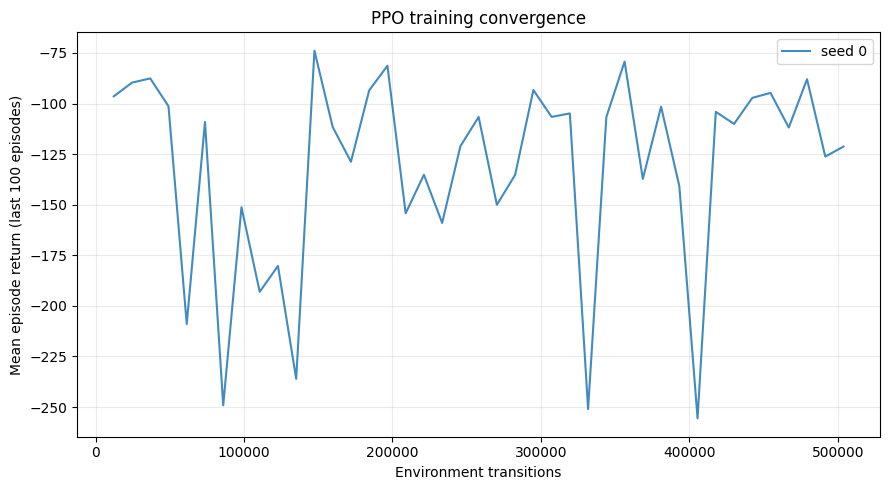

Saved convergence plot: /kaggle/working/outputs/ppo_notebook/ppo_convergence.png


In [10]:
PPO_KWARGS = {
    "n_steps": 4096,
    "batch_size": 512,
    "learning_rate": 2.5e-4,
    "gamma": 0.995,
    "gae_lambda": 0.95,
    "clip_range": 0.2,
    "ent_coef": 0.01,
    "target_kl": 0.03,
    "policy_kwargs": {"net_arch": [256, 256, 128]},
}

class ConvergenceCallback(BaseCallback):
    """Record mean episodic return at each PPO rollout."""
    def __init__(self):
        super().__init__(verbose=0)
        self.timesteps = []
        self.mean_episode_returns = []

    def _on_step(self):
        return True

    def _on_rollout_end(self):
        if self.model.ep_info_buffer:
            self.timesteps.append(int(self.num_timesteps))
            self.mean_episode_returns.append(
                float(np.mean([episode["r"] for episode in self.model.ep_info_buffer]))
            )

def train_one_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    seed_log_dir = OUTPUT_DIR / "monitor" / f"seed_{seed}"
    seed_log_dir.mkdir(parents=True, exist_ok=True)
    env_fns = [
        (lambda name=name: Monitor(
            F1TenthPPOEnv(name, randomize_start=True),
            filename=str(seed_log_dir / name),
        ))
        for name in TRAIN_MAPS
    ]
    vec_env = DummyVecEnv(env_fns)
    vec_env.seed(seed)
    model = PPO("MlpPolicy", vec_env, seed=seed, device="auto", verbose=0, **PPO_KWARGS)
    convergence = ConvergenceCallback()
    model.learn(total_timesteps=TRAINING_STEPS, progress_bar=True, callback=convergence)
    checkpoint = CHECKPOINT_DIR / f"ppo_seed_{seed}"
    model.save(str(checkpoint))
    manifest = {
        "algorithm": "PPO", "seed": seed, "total_timesteps": TRAINING_STEPS,
        "training_maps": TRAIN_MAPS, "randomized_training_starts": True,
        "environment": {
            "control_hz": CONTROL_HZ, "sim_timestep_sec": SIM_TIMESTEP,
            "lidar_dim": LIDAR_DIM, "observation_dim": LIDAR_DIM + 2,
            "observation_features": ["normalized_lidar", "normalized_linear_speed", "normalized_steering_angle"],
            "lidar_max_range_m": LIDAR_MAX_RANGE_M,
            "max_steer_rad": MAX_STEER_RAD, "max_speed_mps": MAX_SPEED_MPS,
            "max_episode_seconds": MAX_EPISODE_SECONDS,
        },
        "reward": {
            "progress_weight": PROGRESS_WEIGHT, "cross_track_weight": CROSS_TRACK_WEIGHT,
            "speed_weight": SPEED_WEIGHT, "time_penalty_per_sec": TIME_PENALTY_PER_SEC,
            "lap_bonus": LAP_BONUS, "collision_penalty": COLLISION_PENALTY,
        },
        "ppo_hyperparameters": {k: v for k, v in PPO_KWARGS.items() if k != "policy_kwargs"},
        "policy_architecture": PPO_KWARGS["policy_kwargs"],
        "versions": {"python": platform.python_version(), "numpy": np.__version__,
                     "torch": torch.__version__,
                     "stable_baselines3": __import__("stable_baselines3").__version__,
                     "gymnasium": gym.__version__},
    }
    checkpoint.with_suffix(".json").write_text(json.dumps(manifest, indent=2))
    vec_env.close()
    return model, str(checkpoint) + ".zip", convergence

trained_models = {}
convergence_runs = {}
for seed in TRAINING_SEEDS:
    trained_models[seed], saved_path, convergence_runs[seed] = train_one_seed(seed)

# PPO convergence: rolling mean episode return, sampled once per rollout.
fig, ax = plt.subplots(figsize=(9, 5))
for seed, trace in convergence_runs.items():
    if trace.timesteps:
        ax.plot(trace.timesteps, trace.mean_episode_returns, label=f"seed {seed}", alpha=0.85)
ax.set(title="PPO training convergence", xlabel="Environment transitions", ylabel="Mean episode return (last 100 episodes)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
convergence_path = OUTPUT_DIR / "ppo_convergence.png"
fig.savefig(convergence_path, dpi=160)
plt.show()
print("Saved convergence plot:", convergence_path)


## Train PPO-LSTM

RecurrentPPO keeps an LSTM state across timesteps. Its state is reset at each episode boundary during evaluation. It uses the same maps, reward, timesteps, and seed list as PPO for a direct comparison.


In [11]:
LSTM_KWARGS = {
    "n_steps": PPO_KWARGS["n_steps"], "batch_size": PPO_KWARGS["batch_size"],
    "learning_rate": PPO_KWARGS["learning_rate"], "gamma": PPO_KWARGS["gamma"],
    "gae_lambda": PPO_KWARGS["gae_lambda"], "clip_range": PPO_KWARGS["clip_range"],
    "ent_coef": PPO_KWARGS["ent_coef"], "target_kl": PPO_KWARGS["target_kl"],
    "policy_kwargs": {"lstm_hidden_size": 128, "n_lstm_layers": 1,
                      "shared_lstm": False, "enable_critic_lstm": True,
                      "net_arch": {"pi": [128], "vf": [128]}},
}

def train_lstm_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    seed_log_dir = OUTPUT_DIR / "monitor_lstm" / f"seed_{seed}"
    seed_log_dir.mkdir(parents=True, exist_ok=True)
    env_fns = [(lambda name=name: Monitor(
        F1TenthPPOEnv(name, randomize_start=True), filename=str(seed_log_dir / name)))
        for name in TRAIN_MAPS]
    vec_env = DummyVecEnv(env_fns)
    vec_env.seed(seed)
    kwargs = dict(LSTM_KWARGS)
    model = RecurrentPPO("MlpLstmPolicy", vec_env, seed=seed, device="auto",
                         verbose=0, **kwargs)
    model.learn(total_timesteps=TRAINING_STEPS, progress_bar=True)
    checkpoint = CHECKPOINT_DIR / f"ppo_lstm_seed_{seed}"
    model.save(str(checkpoint))
    checkpoint.with_suffix(".json").write_text(json.dumps({
        "algorithm": "PPO-LSTM", "seed": seed, "total_timesteps": TRAINING_STEPS,
        "training_maps": TRAIN_MAPS, "randomized_training_starts": True,
        "lstm_hidden_size": 128, "environment": {"observation_dim": LIDAR_DIM + 2},
    }, indent=2))
    vec_env.close()
    return model

trained_lstm_models = {seed: train_lstm_seed(seed) for seed in TRAINING_SEEDS}


Output()

## Offline dataset and IQL

The notebook collects a fixed dataset with a pure-pursuit behavior policy, adds mild action noise, and records the same 130-dimensional observations, normalized actions, and environment rewards used by the online baselines. IQL training below samples only from that saved array; no simulator calls occur in the optimization loop. This is offline policy learning on generated demonstrations, not an offline-only data collection process.

IQL reference: [Kostrikov, Nair, and Levine, Offline Reinforcement Learning with Implicit Q-Learning (2021)](https://arxiv.org/abs/2110.06169). The paper's key steps are expectile value regression, a value-based critic target, and advantage-weighted behavior cloning.


In [12]:
"""Self-contained continuous-control IQL implementation for the notebook.

Algorithm: Kostrikov, Nair, Levine (2021), Offline Reinforcement Learning
with Implicit Q-Learning, https://arxiv.org/abs/2110.06169.
"""
from __future__ import annotations

import copy
from dataclasses import dataclass

import numpy as np
import torch
from torch import nn
from torch.distributions import Normal, TransformedDistribution
from torch.distributions.transforms import TanhTransform


def _mlp(in_dim: int, out_dim: int) -> nn.Sequential:
    return nn.Sequential(nn.Linear(in_dim, 256), nn.ReLU(),
                         nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, out_dim))


class GaussianActor(nn.Module):
    def __init__(self, obs_dim: int, action_dim: int):
        super().__init__()
        self.trunk = nn.Sequential(nn.Linear(obs_dim, 256), nn.ReLU(),
                                   nn.Linear(256, 256), nn.ReLU())
        self.mean = nn.Linear(256, action_dim)
        self.log_std = nn.Parameter(torch.full((action_dim,), -0.5))

    def distribution(self, obs: torch.Tensor) -> TransformedDistribution:
        features = self.trunk(obs)
        mean = self.mean(features)
        std = self.log_std.clamp(-5.0, 2.0).exp().expand_as(mean)
        return TransformedDistribution(Normal(mean, std), [TanhTransform(cache_size=1)])

    def forward(self, obs: torch.Tensor) -> torch.Tensor:
        return torch.tanh(self.mean(self.trunk(obs)))


class QNetwork(nn.Module):
    def __init__(self, obs_dim: int, action_dim: int):
        super().__init__()
        self.net = _mlp(obs_dim + action_dim, 1)

    def forward(self, obs: torch.Tensor, action: torch.Tensor) -> torch.Tensor:
        return self.net(torch.cat((obs, action), dim=-1))


class ValueNetwork(nn.Module):
    def __init__(self, obs_dim: int):
        super().__init__()
        self.net = _mlp(obs_dim, 1)

    def forward(self, obs: torch.Tensor) -> torch.Tensor:
        return self.net(obs)


@dataclass
class IQLConfig:
    obs_dim: int
    action_dim: int = 2
    gamma: float = 0.99
    expectile: float = 0.7
    temperature: float = 3.0
    max_advantage_weight: float = 100.0
    learning_rate: float = 3e-4
    target_tau: float = 0.005


class IQL:
    """IQL learner and deterministic policy loader for vector observations."""
    def __init__(self, config: IQLConfig, device: str = "cpu"):
        self.config = config
        self.device = torch.device(device)
        self.actor = GaussianActor(config.obs_dim, config.action_dim).to(self.device)
        self.q1 = QNetwork(config.obs_dim, config.action_dim).to(self.device)
        self.q2 = QNetwork(config.obs_dim, config.action_dim).to(self.device)
        self.target_q1 = copy.deepcopy(self.q1).requires_grad_(False)
        self.target_q2 = copy.deepcopy(self.q2).requires_grad_(False)
        self.value = ValueNetwork(config.obs_dim).to(self.device)
        self.actor_opt = torch.optim.Adam(self.actor.parameters(), lr=config.learning_rate)
        self.critic_opt = torch.optim.Adam(
            list(self.q1.parameters()) + list(self.q2.parameters()), lr=config.learning_rate)
        self.value_opt = torch.optim.Adam(self.value.parameters(), lr=config.learning_rate)

    def update(self, obs, actions, rewards, next_obs, terminals) -> dict[str, float]:
        obs = torch.as_tensor(obs, dtype=torch.float32, device=self.device)
        actions = torch.as_tensor(actions, dtype=torch.float32, device=self.device)
        rewards = torch.as_tensor(rewards, dtype=torch.float32, device=self.device).reshape(-1, 1)
        next_obs = torch.as_tensor(next_obs, dtype=torch.float32, device=self.device)
        terminals = torch.as_tensor(terminals, dtype=torch.float32, device=self.device).reshape(-1, 1)

        with torch.no_grad():
            q_data = torch.minimum(self.target_q1(obs, actions), self.target_q2(obs, actions))
        value_error = q_data - self.value(obs)
        expectile_weight = torch.where(value_error > 0, self.config.expectile,
                                       1.0 - self.config.expectile)
        value_loss = (expectile_weight * value_error.square()).mean()
        self.value_opt.zero_grad(set_to_none=True)
        value_loss.backward()
        self.value_opt.step()

        with torch.no_grad():
            q_target = rewards + self.config.gamma * (1.0 - terminals) * self.value(next_obs)
        q1_loss = (self.q1(obs, actions) - q_target).square().mean()
        q2_loss = (self.q2(obs, actions) - q_target).square().mean()
        critic_loss = q1_loss + q2_loss
        self.critic_opt.zero_grad(set_to_none=True)
        critic_loss.backward()
        self.critic_opt.step()
        with torch.no_grad():
            for target, source in ((self.target_q1, self.q1), (self.target_q2, self.q2)):
                for target_param, source_param in zip(target.parameters(), source.parameters()):
                    target_param.lerp_(source_param, self.config.target_tau)

        with torch.no_grad():
            advantage = torch.minimum(self.q1(obs, actions), self.q2(obs, actions)) - self.value(obs)
            weights = torch.exp(self.config.temperature * advantage).clamp(max=self.config.max_advantage_weight)
        safe_actions = actions.clamp(-0.999, 0.999)
        actor_loss = -(weights * self.actor.distribution(obs).log_prob(safe_actions).sum(-1, keepdim=True)).mean()
        self.actor_opt.zero_grad(set_to_none=True)
        actor_loss.backward()
        self.actor_opt.step()
        return {"value_loss": float(value_loss.detach()), "critic_loss": float(critic_loss.detach()),
                "actor_loss": float(actor_loss.detach())}

    @torch.no_grad()
    def predict(self, obs: np.ndarray, deterministic: bool = True):
        tensor = torch.as_tensor(np.asarray(obs), dtype=torch.float32, device=self.device)
        if tensor.ndim == 1:
            tensor = tensor.unsqueeze(0)
        dist = self.actor.distribution(tensor)
        action = self.actor(tensor) if deterministic else dist.sample()
        result = action.cpu().numpy()
        return result[0] if np.asarray(obs).ndim == 1 else result

    def save(self, path: str, metadata: dict | None = None) -> None:
        torch.save({"config": self.config.__dict__, "actor": self.actor.state_dict(),
                    "metadata": metadata or {}}, path)

    @classmethod
    def load(cls, path: str, device: str = "cpu") -> tuple["IQL", dict]:
        payload = torch.load(path, map_location=device, weights_only=False)
        learner = cls(IQLConfig(**payload["config"]), device=device)
        learner.actor.load_state_dict(payload["actor"])
        learner.actor.eval()
        return learner, payload.get("metadata", {})


def expectile_loss(diff: torch.Tensor, expectile: float) -> torch.Tensor:
    """Expectile regression loss, exposed for focused numerical checks."""
    weight = torch.where(diff > 0, expectile, 1.0 - expectile)
    return (weight * diff.square()).mean()



In [16]:
def collect_iql_dataset(maps=TRAIN_MAPS, episodes_per_map=8, seed=5000,
                       target_speed_mps=4.0, action_noise_std=0.06):
    """Collect a fixed noisy pure-pursuit dataset without calling PPO policies."""
    rng = np.random.default_rng(seed)
    transitions = {
        key: [] for key in (
            "observations", "actions", "rewards", "next_observations", "terminals"
        )
    }

    for map_name in maps:
        env = F1TenthPPOEnv(map_name, randomize_start=True)
        try:
            for episode in range(episodes_per_map):
                episode_speed = (3.0, 4.0, 5.0)[episode % 3]
                obs, _ = env.reset(seed=seed + episode)
                done = False

                while not done:
                    state = np.asarray(
                        env.sim.sim.agents[0].state, dtype=np.float32
                    )
                    arc, _ = env._project(state[:2])
                    lookahead = float(
                        np.clip(1.0 + 0.18 * max(state[3], 0.0), 1.0, 3.0)
                    )
                    target_arc = (arc + lookahead) % env.total_length
                    idx = max(
                        0,
                        int(np.searchsorted(
                            env.cumulative, target_arc, side="right"
                        ) - 1),
                    )
                    fraction = (
                        (target_arc - env.cumulative[idx])
                        / max(env.segment_lengths[idx], 1e-8)
                    )
                    target_xy = (
                        env.points[idx] + fraction * env.segments[idx]
                    )
                    desired_yaw = np.arctan2(
                        target_xy[1] - state[1], target_xy[0] - state[0]
                    )
                    alpha = (desired_yaw - state[4] + np.pi) % (2 * np.pi) - np.pi
                    steer_rad = np.arctan2(
                        2.0 * 0.33 * np.sin(alpha), lookahead
                    )
                    action = np.array([
                        steer_rad / MAX_STEER_RAD,
                        2.0 * episode_speed / MAX_SPEED_MPS - 1.0,
                    ], dtype=np.float32)
                    action = np.clip(
                        action + rng.normal(0.0, action_noise_std, size=2),
                        -1.0,
                        1.0,
                    )

                    next_obs, reward, terminated, truncated, _ = env.step(action)
                    transitions["observations"].append(obs.copy())
                    transitions["actions"].append(action.copy())
                    transitions["rewards"].append(reward)
                    transitions["next_observations"].append(next_obs.copy())
                    transitions["terminals"].append(float(terminated or truncated))
                    obs = next_obs
                    done = terminated or truncated

                print(
                    f"IQL data: {map_name} episode "
                    f"{episode + 1}/{episodes_per_map}"
                )
        finally:
            env.close()

    return {
        key: np.asarray(value, dtype=np.float32)
        for key, value in transitions.items()
    }

# In Kaggle, upload your .npz file and set this to its path, for example:
# IQL_DATA_PATH = Path("/kaggle/working/my_iql_dataset.npz")
IQL_DATA_PATH = OUTPUT_DIR / "iql_offline_dataset.npz"
LOAD_EXISTING_IQL_DATA = True

IQL_REQUIRED_FIELDS = (
    "observations",
    "actions",
    "rewards",
    "next_observations",
    "terminals",
)


def validate_iql_dataset(dataset):
    missing = [key for key in IQL_REQUIRED_FIELDS if key not in dataset]
    if missing:
        raise ValueError(f"IQL dataset is missing fields: {missing}")

    arrays = {
        key: np.asarray(dataset[key], dtype=np.float32)
        for key in IQL_REQUIRED_FIELDS
    }
    count = len(arrays["rewards"])

    if count == 0 or any(len(value) != count for value in arrays.values()):
        raise ValueError(
            "IQL dataset arrays must have the same nonzero number of transitions"
        )

    expected_obs_dim = LIDAR_DIM + 2
    if arrays["observations"].shape != (count, expected_obs_dim):
        raise ValueError(f"observations must have shape (N, {expected_obs_dim})")
    if arrays["next_observations"].shape != (count, expected_obs_dim):
        raise ValueError(
            f"next_observations must have shape (N, {expected_obs_dim})"
        )
    if arrays["actions"].shape != (count, 2):
        raise ValueError(
            "actions must have shape (N, 2) for [steering, target_speed]"
        )
    if arrays["terminals"].reshape(-1).shape != (count,):
        raise ValueError("terminals must contain one value per transition")
    if not all(np.isfinite(value).all() for value in arrays.values()):
        raise ValueError("IQL dataset contains NaN or infinite values")

    arrays["rewards"] = arrays["rewards"].reshape(-1)
    arrays["terminals"] = arrays["terminals"].reshape(-1)
    return arrays


if LOAD_EXISTING_IQL_DATA and Path(IQL_DATA_PATH).is_file():
    with np.load(IQL_DATA_PATH, allow_pickle=False) as saved_data:
        IQL_DATA = validate_iql_dataset(saved_data)
    print(
        f"Loaded {len(IQL_DATA['rewards']):,} IQL transitions "
        f"from {IQL_DATA_PATH}"
    )
else:
    print("No existing IQL dataset selected/found; collecting a new dataset.")
    IQL_DATA = validate_iql_dataset(collect_iql_dataset())
    Path(IQL_DATA_PATH).parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(IQL_DATA_PATH, **IQL_DATA)
    print(
        f"Saved {len(IQL_DATA['rewards']):,} IQL transitions "
        f"to {IQL_DATA_PATH}"
    )


#IQL_DATA = collect_iql_dataset()
#np.savez_compressed(OUTPUT_DIR / "iql_offline_dataset.npz", **IQL_DATA)
print("Fixed IQL transitions:", len(IQL_DATA["rewards"]))

# Train one IQL policy per seed using the dataset loaded or collected above.
IQL_UPDATES = 100_000
IQL_BATCH_SIZE = 256
IQL_SEEDS = [0]
trained_iql_models = {}

for seed in IQL_SEEDS:
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    learner = IQL(
        IQLConfig(
            obs_dim=LIDAR_DIM + 2,
            action_dim=2,
            gamma=0.99,
            expectile=0.7,
            temperature=3.0,
        ),
        device="cuda" if torch.cuda.is_available() else "cpu",
    )

    if learner.config.action_dim != 2 or learner.actor.mean.out_features != 2:
        raise RuntimeError(
            "IQL policy must output [steering, target_speed]; "
            "rerun this training cell."
        )

    for update in range(1, IQL_UPDATES + 1):
        indices = rng.integers(
            0, len(IQL_DATA["rewards"]), size=IQL_BATCH_SIZE
        )
        losses = learner.update(*(
            IQL_DATA[key][indices]
            for key in (
                "observations",
                "actions",
                "rewards",
                "next_observations",
                "terminals",
            )
        ))

        if update == 1 or update % 5000 == 0:
            print(
                f"IQL seed={seed} update={update}/{IQL_UPDATES} "
                f"losses={losses}"
            )

    checkpoint = CHECKPOINT_DIR / f"iql_seed_{seed}.pt"
    learner.save(
        str(checkpoint),
        {
            "algorithm": "IQL",
            "seed": seed,
            "dataset": "noisy pure pursuit",
            "training_maps": TRAIN_MAPS,
            "dataset_transitions": len(IQL_DATA["rewards"]),
            "observation_dim": LIDAR_DIM + 2,
        },
    )
    trained_iql_models[seed] = learner


Loaded 5,742,044 IQL transitions from /kaggle/working/outputs/ppo_notebook/iql_offline_dataset.npz
Fixed IQL transitions: 5742044
IQL seed=0 update=1/100000 losses={'value_loss': 0.0015812281053513288, 'critic_loss': 0.12279336154460907, 'actor_loss': 0.9184597134590149}
IQL seed=0 update=5000/100000 losses={'value_loss': 0.008502084761857986, 'critic_loss': 15.542375564575195, 'actor_loss': -3.484330654144287}
IQL seed=0 update=10000/100000 losses={'value_loss': 0.012405016459524632, 'critic_loss': 0.05174253135919571, 'actor_loss': -3.063079357147217}
IQL seed=0 update=15000/100000 losses={'value_loss': 0.0238693468272686, 'critic_loss': 0.09613221138715744, 'actor_loss': -4.773309707641602}
IQL seed=0 update=20000/100000 losses={'value_loss': 0.028038978576660156, 'critic_loss': 0.19034157693386078, 'actor_loss': -6.094677448272705}
IQL seed=0 update=25000/100000 losses={'value_loss': 0.035511527210474014, 'critic_loss': 6.516822338104248, 'actor_loss': -4.022831916809082}
IQL seed=

## Matched held-out evaluation

PPO, PPO-LSTM, and IQL are evaluated on the same held-out maps and reproducible start seeds. Success means completing a full lap before collision or timeout. IQL's logged training data uses only `TRAIN_MAPS`; held-out maps are reserved for evaluation.


In [19]:
def available_maps():
    names = []
    for folder in sorted(MAPS_ROOT.iterdir()):
        if not folder.is_dir():
            continue
        try:
            map_files(folder.name)
            names.append(folder.name)
        except FileNotFoundError:
            pass
    return names

EVAL_MAPS = [name for name in available_maps() if name not in TRAIN_MAPS]
if not EVAL_MAPS:
    raise RuntimeError("No held-out maps found. Check maps/ and TRAIN_MAPS.")
print(f"Evaluating {len(EVAL_MAPS)} held-out maps:", EVAL_MAPS)

def evaluate_model(model, method, seed):
    runs = []
    recurrent = method == "PPO-LSTM"
    for map_idx, map_name in enumerate(EVAL_MAPS):
        for episode in range(EVAL_EPISODES_PER_MAP):
            eval_seed = EVAL_BASE_SEED + map_idx * EVAL_EPISODES_PER_MAP + episode
            env = F1TenthPPOEnv(map_name, randomize_start=True)
            try:
                obs, _ = env.reset(seed=eval_seed)
                terminated = truncated = False
                total_reward = speed_sum = target_speed_sum = 0.0
                steps = 0
                info = {}
                recurrent_state = None
                episode_start = np.ones((1,), dtype=bool)
                while not (terminated or truncated):
                    if recurrent:
                        action, recurrent_state = model.predict(obs, state=recurrent_state,
                            episode_start=episode_start, deterministic=True)
                    elif method == "IQL":
                        # The notebook IQL predict() returns the action array directly;
                        # SB3 predict() returns (action, state).
                        action = model.predict(obs, deterministic=True)
                    else:
                        action, _ = model.predict(obs, deterministic=True)

                    action = np.asarray(action, dtype=np.float32).reshape(-1)
                    expected_action_dim = int(np.prod(env.action_space.shape))
                    if action.size != expected_action_dim:
                        model_action_dim = getattr(
                            getattr(model, "config", None), "action_dim", "unknown"
                        )
                        raise ValueError(
                            f"{method} seed {seed} produced {action.size} action value(s), "
                            f"but {map_name} requires {expected_action_dim} "
                            "[steering, target_speed] values. "
                            f"Model config action_dim={model_action_dim}. The IQL model "
                            "in this Kaggle session is stale or was trained with one action "
                            "output. Rerun the IQL dataset selection cell, the IQL training "
                            "cell, and then this evaluation cell using the updated notebook."
                        )
                    obs, reward, terminated, truncated, info = env.step(action)
                    episode_start = np.asarray([terminated or truncated], dtype=bool)
                    total_reward += float(reward)
                    speed_sum += info["speed_mps"]
                    target_speed_sum += info["target_speed_mps"]
                    steps += 1
                runs.append({
                    "method": method, "training_seed": seed,
                    "map_name": map_name, "episode": episode, "seed": eval_seed,
                    "laps_completed": info["laps_completed"], "collision": info["collision"],
                    "elapsed_time_sec": info["elapsed_time_sec"],
                    "lap_times_sec": info["lap_times_sec"], "episode_return": total_reward,
                    "progress_m": info["progress_m"], "total_track_m": info["total_track_m"],
                    "avg_speed_mps": speed_sum / max(steps, 1),
                    "avg_target_speed_mps": target_speed_sum / max(steps, 1),
                })
            finally:
                env.close()
    success = [r for r in runs if r["laps_completed"] > 0]
    lap_times = [t for r in success for t in r["lap_times_sec"]]
    summary = {
        "num_episodes": len(runs), "successes": len(success),
        "success_rate": len(success) / len(runs) if runs else 0.0,
        "collision_count": sum(bool(r["collision"]) for r in runs),
        "collision_rate": float(np.mean([r["collision"] for r in runs])) if runs else 0.0,
        "avg_successful_lap_time_sec": float(np.mean(lap_times)) if lap_times else None,
        "avg_speed_mps": float(np.mean([r["avg_speed_mps"] for r in runs])) if runs else None,
        "avg_target_speed_mps": float(np.mean([r["avg_target_speed_mps"] for r in runs])) if runs else None,
    }
    return {"algorithm": method, "training_seed": seed, "runs": runs, "summary": summary}

# Catch stale one-output IQL objects before starting the long held-out evaluation.
for seed, model in trained_iql_models.items():
    configured_dim = getattr(getattr(model, "config", None), "action_dim", None)
    actor_dim = getattr(getattr(getattr(model, "actor", None), "mean", None), "out_features", None)
    if configured_dim != 2 or actor_dim != 2:
        raise RuntimeError(
            f"IQL seed {seed} has action_dim={configured_dim} and actor output_dim={actor_dim}; "
            "the F1Tenth environment requires two outputs [steering, target_speed]. "
            "Run the updated IQL training cell again before evaluation."
        )

# Add saved SB3 checkpoints here. Paths may include or omit the .zip suffix.
# PPO checkpoints use PPO.load; recurrent checkpoints use RecurrentPPO.load.
# Example: {"algorithm": "PPO", "seed": 0, "path": CHECKPOINT_DIR / "ppo_seed_0.zip"}
CHECKPOINTS_TO_EVALUATE = []
EVALUATE_IN_MEMORY_MODELS = True


def load_evaluation_checkpoint(spec):
    algorithm = str(spec["algorithm"]).upper().replace("_", "-")
    if algorithm not in {"PPO", "PPO-LSTM"}:
        raise ValueError(
            f"Unsupported checkpoint algorithm {algorithm!r}; expected 'PPO' or 'PPO-LSTM'."
        )
    path = Path(spec["path"]).expanduser()
    if not path.is_absolute():
        path = ROOT / path
    if path.suffix != ".zip":
        path = Path(str(path) + ".zip")
    if not path.is_file():
        raise FileNotFoundError(f"{algorithm} checkpoint not found: {path}")
    loader = PPO if algorithm == "PPO" else RecurrentPPO
    model = loader.load(str(path), device="auto")
    # Validate dimensions against this notebook's environment before evaluation.
    if model.observation_space.shape != (LIDAR_DIM + 2,):
        raise ValueError(
            f"Checkpoint {path} expects observations {model.observation_space.shape}; "
            f"this notebook provides {(LIDAR_DIM + 2,)}."
        )
    if model.action_space.shape != (2,):
        raise ValueError(
            f"Checkpoint {path} expects actions {model.action_space.shape}; "
            "the environment requires [steering, target_speed] (2 values)."
        )
    return algorithm, int(spec.get("seed", -1)), model, path


results = {}
if EVALUATE_IN_MEMORY_MODELS:
    for seed, model in trained_iql_models.items():
        results[f"IQL seed {seed}"] = evaluate_model(model, "IQL", seed)
    for seed, model in trained_models.items():
        results[f"PPO seed {seed} (memory)"] = evaluate_model(model, "PPO", seed)
    for seed, model in trained_lstm_models.items():
        results[f"PPO-LSTM seed {seed} (memory)"] = evaluate_model(model, "PPO-LSTM", seed)

for spec in CHECKPOINTS_TO_EVALUATE:
    algorithm, seed, model, checkpoint_path = load_evaluation_checkpoint(spec)
    result = evaluate_model(model, algorithm, seed)
    result["checkpoint"] = str(checkpoint_path)
    results[f"{algorithm} seed {seed} ({checkpoint_path.stem})"] = result

if not results:
    raise RuntimeError(
        "Nothing to evaluate. Enable EVALUATE_IN_MEMORY_MODELS or add checkpoint "
        "entries to CHECKPOINTS_TO_EVALUATE."
    )


aggregate = {}
for metric in ("success_rate", "collision_rate", "avg_successful_lap_time_sec",
               "avg_speed_mps", "avg_target_speed_mps"):
    groups = {}
    for name, entry in results.items():
        groups.setdefault(entry["algorithm"], []).append(entry["summary"][metric])
    aggregate[metric] = {method: {
        "mean": float(np.mean([v for v in values if v is not None])) if any(v is not None for v in values) else None,
        "std": float(np.std([v for v in values if v is not None], ddof=1))
                if sum(v is not None for v in values) > 1 else None,
        "per_seed": values,
    } for method, values in groups.items()}
report = {
    "metadata": {
        "training_maps": TRAIN_MAPS, "evaluation_maps": EVAL_MAPS,
        "training_seeds": TRAINING_SEEDS, "iql_seeds": IQL_SEEDS,
        "checkpoint_specs": [
            {**spec, "path": str(spec["path"])} for spec in CHECKPOINTS_TO_EVALUATE
        ],
        "episodes_per_map": EVAL_EPISODES_PER_MAP,
        "evaluation_base_seed": EVAL_BASE_SEED,
        "success_definition": "at least one complete lap in an episode",
        "start_policy": "seeded randomized centerline point shared by all methods",
        "reward": {"progress_weight": PROGRESS_WEIGHT,
                   "cross_track_weight": CROSS_TRACK_WEIGHT,
                   "speed_weight": SPEED_WEIGHT,
                   "time_penalty_per_sec": TIME_PENALTY_PER_SEC,
                   "lap_bonus": LAP_BONUS, "collision_penalty": COLLISION_PENALTY},
        "iql_dataset": "noisy pure-pursuit trajectories collected in this notebook; fixed during IQL optimization",
    },
    "results": results, "aggregate_across_training_seeds": aggregate,
}
report_path = OUTPUT_DIR / "evaluation_results.json"
report_path.write_text(json.dumps(report, indent=2, allow_nan=False))
print("Saved evaluation report:", report_path)


Evaluating 19 held-out maps: ['BrandsHatch', 'Budapest', 'Catalunya', 'Hockenheim', 'IMS', 'Melbourne', 'Montreal', 'Monza', 'Nuerburgring', 'Oschersleben', 'Sakhir', 'SaoPaulo', 'Sepang', 'Shanghai', 'Silverstone', 'Sochi', 'Spa', 'YasMarina', 'Zandvoort']
-0.07360234


KeyError: 'laps_completed'

In [ ]:
# Compact publication table (seed-level metrics remain in `report`).
rows = []
for name, entry in results.items():
    s = entry["summary"]
    rows.append({"method": name, "success_rate": s["success_rate"],
                 "collision_rate": s["collision_rate"],
                 "avg_successful_lap_time_sec": s["avg_successful_lap_time_sec"],
                 "avg_speed_mps": s["avg_speed_mps"],
                 "avg_target_speed_mps": s["avg_target_speed_mps"]})
pd.DataFrame(rows).sort_values("method")
